## 1. Setup

### 1a. Import Libraries

In [1]:
%load_ext autoreload
%autoreload 2

import os, time, json, zlib, hashlib, random, math, importlib, traceback, fcntl
from pathlib import Path
import numpy as np
import pandas as pd
import pyEDM
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import pearsonr
from scipy.spatial.distance import cdist
from joblib import Parallel, delayed, parallel_config
from tqdm import tqdm
from IPython.display import display
import warnings
warnings.filterwarnings("ignore", category=UserWarning, message="A worker stopped while some jobs were given to the executor")

# pyEDM's own S-map class; only used to check smap_vec against the reference implementation (use_pyedm=True)
SMapClass = importlib.import_module('pyEDM.SMap').SMap

### 1b. Load Datasets

In [2]:
# Synthetic datasets
N = 40
column_names   = [f'{char}{i}' for i in range(1, N + 1) for char in ['X', 'Y', 'Z']]
ecology_df     = pd.read_csv(f'Code and data/Data/data I got from running their code/ecology_data.csv',       header=None, names=['X1', 'Y1', 'Z1'])
lorenz3D_df    = pd.read_csv(f'Code and data/Data/data I got from running their code/lorenz3D.csv',           header=None, names=['X1', 'Y1', 'Z1'])
lorenz120D_df  = pd.read_csv(f'Code and data/Data/data I got from running their code/lorenz120D_eps0.1.csv',  header=None, names=column_names)
rossler120D_df = pd.read_csv(f'Code and data/Data/data I got from running their code/rossler120D_eps0.01.csv', header=None, names=column_names)

# Real-world datasets
road_df        = pd.read_excel('Code and data/Data/Transportation.xlsx', header=None).pipe(lambda df: df.set_axis([f'X{i}' for i in range(1, len(df.columns) + 1)], axis=1))
eeg_df         = pd.read_excel('Code and data/Data/EEG data.xlsx',       header=None)[1:].pipe(lambda df: df.set_axis([f'X{i}' for i in range(1, len(df.columns) + 1)], axis=1))
exchange_df    = pd.read_excel('Code and data/Data/Exchange rates.xlsx', header=None)[2:].pipe(lambda df: df.set_axis([f'X{i}' for i in range(1, len(df.columns) + 1)], axis=1))
wind_df        = pd.read_csv('Code and data/Data/Wind speed.csv'                    ).pipe(lambda df: df.set_axis([f'X{i}' for i in range(1, len(df.columns) + 1)], axis=1))

# Preprocessing
eeg_df = (eeg_df - eeg_df.mean()) / eeg_df.std()
exchange_df = (exchange_df - exchange_df.mean()) / exchange_df.std()
exchange_df = exchange_df.reset_index(drop=True)
exchange_df = exchange_df.astype(float)

# S-map / MVCM settings
DEFAULTS = dict(E_list=[1,5,9], tau_list=[-1,-5,-9], theta_list=[1.,5.,9.], max_views=None)

SYSTEMS = {
    'ecology':      dict(df=ecology_df,     full='X1', E_reported=3, tau_reported=3, **DEFAULTS),
    'lorenz3D':     dict(df=lorenz3D_df,    full='X1', E_reported=3, tau_reported=3, **DEFAULTS),
    'lorenz120D':   dict(df=lorenz120D_df,  full='X1', E_reported=4, tau_reported=3, **DEFAULTS),
    'rossler120D':  dict(df=rossler120D_df, full='X1', E_reported=5, tau_reported=2, **DEFAULTS),
    'road':         dict(df=road_df,        full='X1', E_reported=6, tau_reported=4, **DEFAULTS),
    'eeg':          dict(df=eeg_df,         full='X1', E_reported=3, tau_reported=3, **DEFAULTS),
    'exchange':     dict(df=exchange_df,    full='X1', E_reported=4, tau_reported=4, **DEFAULTS),
    'wind':         dict(df=wind_df,        full='X1', E_reported=4, tau_reported=6, **DEFAULTS),
}

### 1c. Visualize Time Series Data (optional)

In [3]:
# Plot time series data and cross-correlation matrices for each system and saves in the folder "Figures".
make_plots = False       # Change to True to make the figures
output_dir = "Figures"

if make_plots:
    os.makedirs(output_dir, exist_ok=True)

    # Configurations for 3D grouped systems
    systems_3d = [
        {"df": ecology_df,     "system_name": "Ecology", "coupling_strength": None},
        {"df": lorenz3D_df,    "system_name": "Lorenz",  "coupling_strength": None},
        {"df": lorenz120D_df,  "system_name": "Lorenz",  "coupling_strength": 0.1},
        {"df": rossler120D_df, "system_name": "Rossler", "coupling_strength": 0.01},
    ]
    
    # Configurations for 1D grouped systems
    systems_1d = [
        {"df": road_df,     "system_name": "Road"},
        {"df": eeg_df,      "system_name": "EEG"},
        {"df": exchange_df, "system_name": "Exchange"},
        {"df": wind_df,     "system_name": "Wind"},
    ]
    
    # 1. Loop through 3D Systems
    for sys in tqdm(systems_3d, 'Making figures for 3d systems'):
        plot_df = sys["df"]
        system_name = sys["system_name"]
        coupling_strength = sys["coupling_strength"]
        n_dim = len(plot_df.columns)
    
        w_suffix = f"_w{coupling_strength}" if coupling_strength is not None else ""
        title_coupling = rf" ($\omega$={coupling_strength})" if coupling_strength is not None else ""
    
        # Time series trajectories
        fig, ax = plt.subplots(3, 1, figsize=(7, 5), sharex=True, dpi=300)
        names = ['X', 'Y', 'Z']
        panel_labels = ['(a)', '(b)', '(c)']
        for axi, name in enumerate(names):
            x_cols = [col for col in plot_df.columns if col.startswith(name)]
            for col in x_cols:
                ax[axi].plot(plot_df.index, plot_df[col], linewidth=0.5, alpha=0.5)
            ax[axi].set_ylabel(f"{name} Components")
            ax[axi].text(0.01, 1.0, panel_labels[axi], transform=ax[axi].transAxes, va='top')
            ax[axi].spines['top'].set_visible(False)
            ax[axi].spines['right'].set_visible(False)
            ax[axi].grid(True, linestyle=':', alpha=0.4, color='gray')
    
        ax[-1].set_xlabel("Time Step (t)")
        ax[0].set_title(f"{n_dim}-Dimensional {system_name} System Trajectories{title_coupling}", y=0.98, pad=15)
        fig.align_ylabels(ax)
        fig.tight_layout()
    
        if make_plots:
            plt.savefig(os.path.join(output_dir, f"{system_name}_{n_dim}d_trajectories{w_suffix}.png"), bbox_inches='tight', dpi=300)
    
        # Correlation matrix heatmap
        x_cols = sorted([col for col in plot_df.columns if col.startswith('X')])
        y_cols = sorted([col for col in plot_df.columns if col.startswith('Y')])
        z_cols = sorted([col for col in plot_df.columns if col.startswith('Z')])
        ordered_cols = x_cols + y_cols + z_cols
    
        corr_matrix = plot_df[ordered_cols].corr()
        num_x, num_y, num_z = len(x_cols), len(y_cols), len(z_cols)
        boundaries = [num_x, num_x + num_y]
    
        fig, ax = plt.subplots(figsize=(6, 5), dpi=300)
        sns.heatmap(
            corr_matrix, cmap="coolwarm", vmin=-1.0, vmax=1.0, center=0, square=True,
            cbar_kws={"label": "Pearson Correlation Coefficient ($r$)", "shrink": 0.82, "ticks": [-1.0, -0.5, 0.0, 0.5, 1.0]},
            xticklabels=False, yticklabels=False, ax=ax
        )
    
        for b in boundaries:
            ax.axhline(b, color="white", linewidth=1.5)
            ax.axvline(b, color="white", linewidth=1.5)
    
        block_centers = [num_x / 2, num_x + (num_y / 2), num_x + num_y + (num_z / 2)]
        block_names = ["X Components", "Y Components", "Z Components"]
        ax.set_xticks(block_centers)
        ax.set_xticklabels(block_names)
        ax.set_yticks(block_centers)
        ax.set_yticklabels(block_names, rotation=0)
        ax.tick_params(axis="both", which="both", length=0)
        ax.set_title(f"{n_dim}-Dimensional {system_name} System Correlation Matrix", pad=10)
    
        plt.tight_layout()
        if make_plots:
            plt.savefig(os.path.join(output_dir, f"{system_name}_{n_dim}d_corr_matrix{w_suffix}.png"), bbox_inches='tight', dpi=300)
    
    # 2. Loop through 1D Systems
    for sys in tqdm(systems_1d, desc='Making figures for 1d systems'):
        plot_df = sys["df"]
        system_name = sys["system_name"]
        n_dim = len(plot_df.columns)
    
        # Time series trajectories
        fig, ax = plt.subplots(1, 1, figsize=(7, 3.5), dpi=300)
        for col in plot_df.columns:
            ax.plot(plot_df.index, plot_df[col], linewidth=0.5, alpha=0.2)
        ax.set_xlabel("Time Step ($t$)")
        ax.set_ylabel("Value")
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.grid(True, linestyle=':', alpha=0.4, color='gray')
        ax.set_title(f"{n_dim}-Dimensional {system_name} System Trajectories", pad=12)
    
        fig.tight_layout()
        if make_plots:
            plt.savefig(os.path.join(output_dir, f"{system_name}_{n_dim}d_trajectories.png"), bbox_inches='tight', dpi=300)
    
        # Correlation matrix heatmap
        corr_matrix = plot_df.corr()
        num_vars = len(plot_df.columns)
    
        fig, ax = plt.subplots(figsize=(6, 5), dpi=300)
        sns.heatmap(
            corr_matrix, cmap="coolwarm", vmin=-1.0, vmax=1.0, center=0, square=True,
            cbar_kws={"label": "Pearson Correlation Coefficient ($r$)", "shrink": 0.82, "ticks": [-1.0, -0.5, 0.0, 0.5, 1.0]},
            xticklabels=False, yticklabels=False, ax=ax
        )
    
        tick_positions = [0, num_vars // 4, num_vars // 2, (3 * num_vars) // 4, num_vars]
        tick_labels = [1, num_vars // 4, num_vars // 2, (3 * num_vars) // 4, num_vars]
        ax.set_xticks(tick_positions)
        ax.set_xticklabels(tick_labels)
        ax.set_yticks(tick_positions)
        ax.set_yticklabels(tick_labels, rotation=0)
        ax.set_xlabel("X")
        ax.set_ylabel("X")
        ax.set_title(f"{n_dim}-Dimensional {system_name} Correlation Matrix", pad=10)
    
        plt.tight_layout()
        if make_plots:
            plt.savefig(os.path.join(output_dir, f"{system_name}_{n_dim}d_corr_matrix.png"), bbox_inches='tight', dpi=300)

### 1d. Method Names and Colors

In [4]:
# Method names, labels and colours shared by the examples, tables and plots
METHOD_ORDER  = ('smap', 'mvcm', 'fprm')
METHOD_LABELS = {'smap': 'S-map', 'mvcm': 'MVCM', 'fprm': 'FPRM'}
METHOD_COLORS = dict(zip(METHOD_ORDER, ['tab:orange', 'tab:green', 'tab:red']))

## 2. Shared Functions

* `smap_vec` - vectorized S-map implementation.
* `make_observed` – draws the random missingness mask.
* `evaluate_view` – given an embedding, runs S-map over a list of θ values and returns ρ and the predictions.
  `mode='train'` predicts the training rows from the other training rows (optionally with `exclusionRadius`);
  `mode='test'` predicts the held-out rows from the training rows.
* `_metrics` – ρ, RMSE and nRMSE (RMSE / SD of the truth) of a set of predictions.

In [5]:
def smap_vec(Z, y, lib_i, pred_i, thetas, knn=None, Tp=0, exclusion_radius=0, valid_lib=None):
    """
    Vectorized S-map logic that reproduces the prediction output of pyEDM.SMap(embedded=True, noTime=True) across a range of thetas. 
    Runs about 2x faster.
    
    INPUTS:
    Z                : ndarray (N, d)                 | State space embedding.
    y                : ndarray (N,)                   | Target vector.
    lib_i, pred_i    : array_like                     | 0-based row indices defining library and prediction indices.
    thetas           : float or array_like            | S-map nonlinearity parameter
    knn              : int, optional                  | Number of nearest neighbors to retain. Defaults to len(lib) - 1
    Tp               : int, default=0                 | Prediction horizon applied to library target index (y[lib_i + Tp]).
    exclusion_radius : int, default=0                 | Exclude library rows within |pred_i - lib_i| <= exclusion_radius
    valid_lib        : array_like of bool, optional   | Optional boolean mask indicating valid library rows (matches pyEDM validLib)
    
    OUTPUTS:
    preds            : ndarray (n_theta, len(pred_i)) | Predicted target values aligned with pred_i (NaN where rows are dropped/invalid).
    """
    lib_i = np.asarray(lib_i, int)
    pred_i = np.asarray(pred_i, int)

    # Identify rows in Z without any NaNs
    valid_rows = ~np.isnan(Z).any(axis=1)
    lib_ok = lib_i[valid_rows[lib_i]]
    pred_ok_mask = valid_rows[pred_i]
    pred_ok = pred_i[pred_ok_mask]

    lib_all_n = len(lib_i)

    # Determine default knn according to pyEDM rules
    if knn is None:
        # Default is total library rows - 1 (or valid library rows -1 if NaNs exist)
        knn = (len(lib_ok) - 1 if len(lib_ok) < lib_all_n else lib_all_n - 1)

    # Determine candidate lookup window (k_query)
    if valid_lib is not None:
        lib_ok = lib_ok[np.asarray(valid_lib)[lib_ok]]
        if len(lib_ok) < knn:
            raise ValueError('valid library smaller than knn')
        k_query = None
    else:
        # Check if prediction rows overlap with library rows
        has_overlap = np.isin(pred_ok, lib_ok).any()
        if exclusion_radius > 0:
            k_query = min(knn * 5, len(lib_ok))
        else:
            k_query = knn + 1 if has_overlap else knn

    # Distance matrix (pred_ok x lib_ok)
    D = cdist(Z[pred_ok], Z[lib_ok], metric='euclidean')

    # Run batched S-map fit and prediction
    res = smap_core(D, Z[lib_ok], Z[pred_ok], y[lib_ok + Tp], lib_ok, pred_ok, thetas, knn,
                    exclusion_radius, k_query)

    # Format output matrices to match original 'pred_i' input shape (inserting NaNs for invalid rows)
    n_thetas = len(np.atleast_1d(thetas))
    out = np.full((n_thetas, len(pred_i)), np.nan)
    out[:, pred_ok_mask] = res
    return out

def smap_core(D, Zlib, Zpred, ylib, lib_i, pred_i, thetas, knn, exclusion_radius=0, k_query=None, chunk_elems=2e7):
    """
    Core numerical routine for S-map neighbor selection, weight assignment, and batch solving.
    
    INPUTS:
    D                : ndarray (P, L)                 | Euclidean distances pred x lib (no NaN: drop NaN-embedding rows/cols first).
    Zlib             : ndarray (L, d)                 | Library embedding.
    Zpred            : ndarray (L, d)                 | Prediction embedding.
    ylib             : ndarray (L,)                   | target at lib rows + Tp (NaN allowed; those neighbors are dropped from the fit)
    lib_i, pred_i    : array_like                     | original row indices (used for exclusion_radius).
    k_query          : int                            | pyEDM over-query size when NOT using validLib (None = consider every lib row)

    OUTPUTS:
    preds            : ndarray (n_theta, P)           | S-map predictions for each theta value.
    """
    thetas = np.atleast_1d(np.asarray(thetas, float))
    P, L = D.shape     # P prediction points, L library candidates
    d = Zlib.shape[1]  # Embedding dimension
    K = d + 1          # Number of coefficients (intercept + E features)

    # 1. Candidate pre-filtering (k_query limit)
    Dm = D.copy()
    if k_query is not None and k_query < L:
        # Find the k-query-th smallest distance for each prediction row
        kth = np.partition(D, k_query - 1, axis=1)[:, k_query - 1 : k_query]
        Dm[D > kth] = np.inf  # Mask out candidates further than k_query-th neighbor

    # 2. Temporal exclusion radius - mask out library rows too close to prediction target (|pred_i - lib_i| <= radius)
    temporal_dist = np.abs(pred_i[:, None] - lib_i[None, :])
    Dm[temporal_dist <= exclusion_radius] = np.inf

    # 3. Top-knn selection
    sel = np.isfinite(Dm)
    drop = np.maximum(sel.sum(1) - knn, 0)
    if drop.max(initial=0) > 0:
        if drop.max() == 1:
            # Fast path: exactly 1 neighbor to drop (e.g., knn = n_lib - 1)
            far = np.where(sel, Dm, -np.inf).argmax(1)
            r = np.where(drop > 0)[0]
            Dm[r, far[r]] = np.inf
        else:
            # Fallback path: drop multiple neighbors using stable rank
            rank = np.argsort(np.argsort(Dm, axis=1, kind='stable'), axis=1, kind='stable')
            Dm[rank >= knn] = np.inf
        sel = np.isfinite(Dm)
        
    # 4. Compute mean neighbor distance per row
    cnt = sel.sum(1)
    Dz = np.where(sel, Dm, 0.0)
    dmean = np.where(cnt > 0, Dz.sum(1) / np.maximum(cnt, 1), np.nan)

    # 5. Target mask and matrix preparation
    yfin = np.isfinite(ylib)
    valid = sel & yfin[None, :]       # Valid neighbor if finite distance AND finite target
    rows = np.where(valid.any(1))[0]  # Prediction rows with at least 1 valid neighbor
    M = valid.sum(1)                  # Count of usable neighbors per prediction point

    # Design matrix augmentation [1, Zlib] for intercept term
    Zaug = np.hstack([np.ones((L, 1)), Zlib])  # (L, K)
    yz = np.where(yfin, ylib, 0.0)

    # Compute batch chunk size to manage RAM allocation
    step = max(1, int(chunk_elems // (L * K)))

    # 6. Local linear model fitting across theta values
    preds = np.full((len(thetas), P), np.nan)
    for t, theta in enumerate(thetas):
        for s0 in range(0, len(rows), step):
            r = rows[s0: s0 + step]
            
            # Compute S-map exponential weights: W = exp(-theta * d / d_mean)
            if theta == 0:
                W = valid[r].astype(float)
            else:
                scale = (theta / dmean[r])[:, None]
                W = np.where(valid[r], np.exp(-scale * Dz[r]), 0.0)

            # Weight the design matrix A and target vector b
            A = W[:, :, None] * Zaug[None, :, :]
            b = W * yz[None, :]

            # Fit local minimum-norm linear regression via SVD
            C = _solve_svd(A, b, M[r])

            # Local prediction: c0 + sum_e (c_e * Zpred[e])
            preds[t, r] = C[:, 0] + np.einsum('pk,pk->p', C[:, 1:], Zpred[r])
    return preds

_EPS = np.finfo(float).eps

def _solve_svd(A, b, M):
    """Batched min-norm least squares solver via SVD. Replicates numpy `np.linalg.lstsq` / LAPACK `gelsd` singular value cutoff logic:
       cutoff = eps * max(M, K) * s_max"""
    K = A.shape[2]
    U, s, Vt = np.linalg.svd(A, full_matrices=False)
    cutoff = (_EPS * np.maximum(M, K))[:, None] * s[:, :1]
    sinv = np.where(s > cutoff, 1.0 / np.where(s > 0, s, 1.0), 0.0)
    Utb = np.einsum('plk,pl->pk', U, b)
    return np.einsum('pkj,pk->pj', Vt, sinv * Utb)

In [6]:
def make_observed(df, missing_frac, full, seed):
    """Create boolean mask of where df was observed, based on the missingness fraction and random seed."""
    rng = np.random.default_rng(seed)
    is_observed = pd.DataFrame(rng.random(size=df.shape) >= missing_frac, index=df.index, columns=df.columns)
    is_observed[full] = True
    return is_observed

In [7]:
def evaluate_view(df, block, columns, target, maskTrn, maskTest, E, theta_list, exclusionRadius, mode, use_pyedm=False):
    """Evaluate S-map embedding over a list of theta values."""
    maskTrn = np.asarray(maskTrn)
    pred_rows = np.where(maskTrn if mode == 'train' else ~maskTrn)[0]

    X = block.loc[:, columns].copy()
    Y = df[target].copy()
    
    if mode == 'train': # Ensure no testing data is getting into the S-map
        X.loc[~maskTrn, :] = np.nan
        Y.loc[~maskTrn] = np.nan

    # Standardize embedding columns using training data stats
    mu, sigma = X[maskTrn].mean(), X[maskTrn].std(axis=0, ddof=0)
    Z = (X - mu) / np.where(sigma == 0, 1.0, sigma)

    n_lib = int((maskTrn & Z.notna().all(axis=1).to_numpy()).sum())
    if n_lib < 3:
        return []
    knn = n_lib - 1

    # -------------------------------------------------------------------
    # pyEDM Implementation - used for verification only 
    # -------------------------------------------------------------------
    if use_pyedm:
        df_edm = pd.concat([Z, Y], axis=1).reset_index(drop=True)

        # Pre-compute neighbors and distances for fast theta sweep
        smap_obj = SMapClass(
            dataFrame=df_edm, columns=list(Z.columns), target=target,
            lib=f'1 {len(df_edm)}', pred=f'1 {len(df_edm)}', validLib=maskTrn, knn=knn,
            Tp=0, theta=0, exclusionRadius=exclusionRadius if mode == 'train' else 0,
            embedded=True, noTime=True
        )
        smap_obj.EmbedData()
        smap_obj.RemoveNan()
        smap_obj.FindNeighbors()

        view_theta_sweep = []
        for theta in theta_list:
            smap_obj.theta = theta
            smap_obj.Project()
            smap_obj.FormatProjection()

            P = smap_obj.Projection
            row = P['Time'].to_numpy() - 1
            pred_df = (P.assign(row=row).loc[np.isin(row, pred_rows), ['row', 'Observations', 'Predictions']].dropna().set_index('row'))

            m = _metrics(pred_df['Observations'], pred_df['Predictions'])
            view_theta_sweep.append({'E': E, 'embedding': columns, 'theta': theta, 
                                     'rho': m['rho'], 'rmse': m['rmse'], 'nrmse': m['nrmse'],
                                     'preds': pred_df, 'n_preds': len(pred_df)})
            
    # -------------------------------------------------------------------
    # Vectorized S-map Implementation
    # -------------------------------------------------------------------
    else:
        Z = Z.to_numpy(float)
        Y = Y.to_numpy(float)
        preds = smap_vec(Z, Y, lib_i = np.arange(len(X)), pred_i=pred_rows, thetas=theta_list, knn=knn,
                        exclusion_radius=exclusionRadius if mode == 'train' else 0, valid_lib=maskTrn)

        view_theta_sweep = []
        for t, theta in enumerate(theta_list):
            pred_df = pd.DataFrame({'Observations': Y[pred_rows], 'Predictions': preds[t]},
                                   index=pd.Index(pred_rows, name='row')).dropna()

            m = _metrics(pred_df['Observations'], pred_df['Predictions'])
            view_theta_sweep.append({'E': E, 'embedding': columns, 'theta': theta, 
                                     'rho': m['rho'], 'rmse': m['rmse'], 'nrmse': m['nrmse'],
                                     'preds': pred_df, 'n_preds': len(pred_df)})
    
    return view_theta_sweep

In [8]:
def _metrics(y, p):
    """rho, RMSE and nRMSE (RMSE / SD of the truth) of predictions p against truth y. NaN if there are <3 points or p is constant."""
    y, p = np.asarray(y, float), np.asarray(p, float)
    if len(y) < 3 or np.std(p) == 0:
        return dict(rho=np.nan, rmse=np.nan, nrmse=np.nan)
    rmse = float(np.sqrt(np.mean((y - p) ** 2)))
    return dict(rho=float(np.corrcoef(y, p)[0, 1]), rmse=rmse, nrmse=rmse / float(np.std(y)))

## 3. S-Map Imputation

In [9]:
def smap_impute(df, missing_frac, full, partial, E_list, tau_list, theta_list, exclusionRadius, 
                showPlot=False, seed=None, use_pyedm=True):
    """S-map imputation of the partial variable using the full variable."""

    # Train/test partitioning (remove missing_frac from partial)
    is_observed = make_observed(df, missing_frac, full, seed)
    maskTrn, maskTest = is_observed[partial].to_numpy(), ~is_observed[partial].to_numpy()

    # Parameter selection using training data (chooses E, tau, theta)
    records = []
    for E in E_list:
        for tau in tau_list:
            block = pyEDM.Embed(dataFrame=df, columns=full, E=E, tau=tau)
            theta_sweep = evaluate_view(
                df=df, block=block, columns=list(block.columns), target=partial,
                maskTrn=maskTrn, maskTest=maskTest, E=E, theta_list=theta_list,
                exclusionRadius=exclusionRadius, mode='train', use_pyedm=use_pyedm
            )
            for item in theta_sweep:
                records.append({'E': E, 'tau': tau, 'theta': item['theta'], 'rho': item['rho'], 'nrmse': item['nrmse']})
                
    parameter_grid = pd.DataFrame(records).sort_values(by='rho', ascending=False).reset_index(drop=True)
    best = parameter_grid.iloc[0]
    best_E, best_tau, best_theta = int(best['E']), int(best['tau']), float(best['theta'])

    # Final imputation using best parameters
    best_block = pyEDM.Embed(dataFrame=df, columns=full, E=best_E, tau=best_tau)
    final_prediction = evaluate_view(
        df=df, block=best_block, columns=list(best_block.columns), target=partial,
        maskTrn=maskTrn, maskTest=maskTest, E=best_E, theta_list=[best_theta],
        exclusionRadius=exclusionRadius, mode='test', use_pyedm=use_pyedm
    )
    pred_df = final_prediction[0]['preds']

    # Get output DataFrame and summary statistics
    original_series = df[partial].values
    imputed_series = np.full(len(df), np.nan)
    imputed_series[pred_df.index] = pred_df['Predictions'].values

    result_df = pd.DataFrame({
        f'{partial}_complete': original_series,
        f'{partial}_observed': np.where(maskTrn, original_series, np.nan),
        f'{partial}_imputed': imputed_series
    }, index=df.index)

    eval_df = result_df[[f'{partial}_complete', f'{partial}_imputed']].dropna()
    true_vals, imputed_vals = eval_df[f'{partial}_complete'].values, eval_df[f'{partial}_imputed'].values
    m = _metrics(true_vals, imputed_vals)
    rho, nrmse = m['rho'], m['nrmse']

    if showPlot:
        fig, ax = plt.subplots(figsize=(12, 4))
        result_df.plot(y=f'{partial}_complete', ax=ax, alpha=0.5, c='gray')
        result_df.plot(y=f'{partial}_imputed', ax=ax, marker='.', markersize=3, ls='None', c=METHOD_COLORS['smap'])
        ax.set_title(f'{partial} S-Map Imputation (E={best_E}, tau={best_tau}, theta={best_theta})\nρ={rho:.3f}, nRMSE={nrmse:.3f} (N={len(eval_df)})')
        plt.show()

    return {
        'params': {'E': best_E, 'tau': best_tau, 'theta': best_theta},
        'metrics': {'rho': rho, 'nrmse': nrmse, 'N': len(imputed_vals)},
        'train_rho': float(best['rho']),          # rho of the chosen (E, tau, theta) on the training rows
        'train_nrmse': float(best['nrmse']),
        'parameter_grid': parameter_grid,
        'result_df': result_df
    }

## 4. MVCM Imputation

### 4a. Helper Functions

* `get_embedding_list` - finds embeddings that will be able to fill gaps in the partial time series. Exhaustive or random search.
* `build_embedding_block` - builds a lag block (DataFrame with columns X1(t-`numLags` * `lagTau`), ..., X1(t+`numLags` * `lagTau`)).

In [10]:
def get_embedding_list(maskTrn, maskTest, block, E, rng, min_candidates_per_gap, min_train_overlap,
                       max_combos_per_row_pass=3, exhaustive=False, max_embeddings=1e6, verbose=True):
    """
    Get a master list of randomly selected embeddings such that:
    1. Every embedding covers >= min_train_overlap rows in the training set.
    2. Every index is covered by >= min_candidates_per_gap views (if feasible).
    If exhaustive = True, constructs and filters all valid combinations directly.
    verbose = False silences the printed warnings; the same information is always returned in `diagnostics`.
    """
    col_names = np.array(block.columns)
    is_observed = ~block.isna().to_numpy()

    train_rows = np.where(maskTrn)[0]
    test_rows = np.where(maskTest)[0]

    # Pre-filter eligible columns (at least min_train_overlap observations in the train set)
    n_train_per_col = is_observed[train_rows].sum(axis=0)
    eligible_cols = np.where(n_train_per_col >= min_train_overlap)[0]

    if len(eligible_cols) < E:
        if verbose:
            print(f'Not enough eligible columns to create embeddings for E={E}. Try increasing numLags or lagTau to get more columns.')
        return None, {'skipped': f'fewer than E={E} eligible columns', 'n_eligible_cols': int(len(eligible_cols))}

    obs_train = is_observed[train_rows][:, eligible_cols]  # where block[train_rows] has observations (boolean array)
    obs_test = is_observed[test_rows][:, eligible_cols]    # where block[test_rows] has observations (boolean array)

    # Filter fillable rows for both train and test sets
    fillable_trn_mask = obs_train.sum(axis=1) >= E
    fillable_test_mask = obs_test.sum(axis=1) >= E

    obs_fillable_trn = obs_train[fillable_trn_mask]
    obs_fillable_test = obs_test[fillable_test_mask]

    # ----------------------------------------------------------------------------------------
    # FILTER EMBEDDINGS FOR CRITERION 1: Covers >= min_train_overlap rows in the training set
    # ----------------------------------------------------------------------------------------
    # pair_overlap[i, j] = number of train rows where both col_i and col_j are observed
    pair_overlap = obs_train.astype(int).T @ obs_train.astype(int)
    valid_pair_adj = pair_overlap >= min_train_overlap

    def passes_criterion_1(combo):
        for i in range(E):
            for j in range(i+1, E):
                if not valid_pair_adj[combo[i], combo[j]]:
                    return False
        joint_overlap = (obs_train[:, list(combo)].sum(axis=1) == E).sum()
        return joint_overlap >= min_train_overlap

    def compatible_combos(candidates, E):
        """Generate combinations of size E from the candidates."""
        def extend(combo, available_indices):
            if len(combo) == E:
                yield tuple(sorted(combo))
                return
            for i, idx in enumerate(available_indices):
                c = candidates[idx]
                if all(valid_pair_adj[c, x] for x in combo):
                    # Pass only the positional indices AFTER the current one to avoid duplicate pairs
                    new_available = available_indices[i + 1:]
                    yield from extend(combo + (c,), new_available)
        yield from extend((), np.arange(len(candidates)))

    # ----------------------------------------------------------------------------------------
    # EXHAUSTIVE SEARCH OPTION
    # ----------------------------------------------------------------------------------------
    M_eligible = len(eligible_cols)
    total_raw_combos = math.comb(M_eligible, E)
    if exhaustive:
        if total_raw_combos > max_embeddings and verbose:
            print(f'WARNING: Exhaustive search space for E={E} has {total_raw_combos} raw combinations.')

        # Prune valid combos using pairwise adjacency matrix
        valid_combos = []
        def build_combos(current_combo, start_idx):
            if len(current_combo) == E:
                valid_combos.append(current_combo)
                return
            for i in range(start_idx, M_eligible):
                if all(valid_pair_adj[i, c] for c in current_combo):
                    build_combos(current_combo + (i,), i + 1)
        build_combos((), 0)

        # Filter for Criterion 1
        selected_combos = []
        for combo in valid_combos:
            joint_overlap = (obs_train[:, list(combo)].sum(axis=1) == E).sum()
            if joint_overlap >= min_train_overlap:
                selected_combos.append(combo)
        embeddings = [tuple(col_names[eligible_cols[list(c)]]) for c in selected_combos]

        # Vectorized diagnostic coverage calculation
        if len(selected_combos) > 0:
            combo_matrix = np.array(selected_combos)  # Shape: (n_combos, E)
            
            # Broadcast check: does each combo cover each fillable row?
            views_per_test_row = np.zeros(len(obs_fillable_test), dtype=int)
            views_per_trn_row = np.zeros(len(obs_fillable_trn), dtype=int)
            
            for combo in selected_combos:
                views_per_test_row += (obs_fillable_test[:, list(combo)].sum(axis=1) == E)
                views_per_trn_row += (obs_fillable_trn[:, list(combo)].sum(axis=1) == E)
        else:
            views_per_test_row = np.zeros(len(obs_fillable_test), dtype=int)
            views_per_trn_row = np.zeros(len(obs_fillable_trn), dtype=int)
            
        diagnostics = {
            "n_embeddings": len(embeddings),
            "n_trn_total": len(train_rows),
            "n_test_total": len(test_rows),
            "n_trn_fillable": int(fillable_trn_mask.sum()),
            "n_test_fillable": int(fillable_test_mask.sum()),
            "unfillable_trn_rows": train_rows[~fillable_trn_mask].tolist(),
            "unfillable_test_rows": test_rows[~fillable_test_mask].tolist(),
            "undercovered_test_rows": dict(zip(test_rows[fillable_test_mask][views_per_test_row < min_candidates_per_gap].tolist(),
                                               views_per_test_row[views_per_test_row < min_candidates_per_gap].tolist(),)),
            "undercovered_trn_rows": dict(zip(train_rows[fillable_trn_mask][views_per_trn_row < min_candidates_per_gap].tolist(),
                                              views_per_trn_row[views_per_trn_row < min_candidates_per_gap].tolist(),)),}
        diagnostics['n_eligible_cols'] = int(len(eligible_cols))
        if verbose:
            print_diagnostic_warnings(diagnostics, min_candidates_per_gap)
        return embeddings, diagnostics
        
    # ----------------------------------------------------------------------------------------
    # RANDOM SEARCH OPTION - FIND MIN_CANDIDATES_PER_GAP EMBEDDINGS TO FILL EACH GAP
    # ----------------------------------------------------------------------------------------
    selected_combos = set()
    views_per_test_row = np.zeros(len(obs_fillable_test), dtype=int)
    views_per_trn_row = np.zeros(len(obs_fillable_trn), dtype=int)

    # Combine rows needing coverage (process test gaps first, then train gaps)
    all_target_obs = np.vstack([obs_fillable_test, obs_fillable_trn])
    is_test_flag = np.array([True] * len(obs_fillable_test) + [False] * len(obs_fillable_trn))

    while True:
        # Identify rows that still need candidate coverage
        test_needy = views_per_test_row < min_candidates_per_gap
        trn_needy = views_per_trn_row < min_candidates_per_gap
        needy_mask = np.concatenate([test_needy, trn_needy])
        needy_indices = np.where(needy_mask)[0]

        # Stop if every fillable gap index has reached target coverage
        if len(needy_indices) == 0:
            break

        # Shuffle needy row order each pass for random exploration
        needy_indices = rng.permutation(needy_indices)
        added_in_this_pass = 0

        for row_idx in needy_indices:
            # Skip if this target row reached capacity during the current pass
            if is_test_flag[row_idx]:
                if views_per_test_row[row_idx] >= min_candidates_per_gap:
                    continue
            else:
                trn_idx = row_idx - len(obs_fillable_test)
                if views_per_trn_row[trn_idx] >= min_candidates_per_gap:
                    continue

            # Get ONLY the columns observed for this row
            row_obs_cols = np.where(all_target_obs[row_idx] == 1)[0]
            if len(row_obs_cols) < E:
                continue

            # Shuffle feature candidates for this row attempt
            shuffled_cols = rng.permutation(row_obs_cols)
            row_added = 0

            for combo in compatible_combos(shuffled_cols, E):
                sorted_combo = tuple(sorted(combo))

                if sorted_combo in selected_combos:
                    continue

                if not passes_criterion_1(sorted_combo):
                    continue

                selected_combos.add(sorted_combo)
                added_in_this_pass += 1
                row_added += 1

                # Update coverage counters for training and test sets
                covers_test = obs_fillable_test[:, list(sorted_combo)].sum(axis=1) == E
                covers_trn = obs_fillable_trn[:, list(sorted_combo)].sum(axis=1) == E
    
                views_per_test_row += covers_test.astype(int)
                views_per_trn_row += covers_trn.astype(int)

                # Cap contribution for this row in the current pass
                if row_added >= max_combos_per_row_pass:
                    break

                if len(selected_combos) >= max_embeddings:
                    break

            if len(selected_combos) >= max_embeddings:
                break

        # Safety exit: break if a full pass across all needy rows produced 0 new embeddings
        if added_in_this_pass == 0 or len(selected_combos) >= max_embeddings:
            break

    selected_list = list(selected_combos)
    embeddings = [tuple(col_names[eligible_cols[list(c)]]) for c in selected_list]

    # Diagnostics
    test_undercovered_mask = views_per_test_row < min_candidates_per_gap
    trn_undercovered_mask = views_per_trn_row < min_candidates_per_gap
    
    undercovered_test_indices = test_rows[fillable_test_mask][test_undercovered_mask].tolist()
    undercovered_trn_indices = train_rows[fillable_trn_mask][trn_undercovered_mask].tolist()
    
    test_counts = views_per_test_row[test_undercovered_mask].tolist()
    trn_counts = views_per_trn_row[trn_undercovered_mask].tolist()

    diagnostics = {
        'n_embeddings': len(embeddings),
        'n_trn_total': len(train_rows),
        'n_test_total': len(test_rows),
        'n_trn_fillable': int(fillable_trn_mask.sum()),
        'n_test_fillable': int(fillable_test_mask.sum()),
        'unfillable_trn_rows': train_rows[~fillable_trn_mask].tolist(),
        'unfillable_test_rows': test_rows[~fillable_test_mask].tolist(),
        'undercovered_test_rows': dict(zip(undercovered_test_indices, test_counts)),
        'undercovered_trn_rows': dict(zip(undercovered_trn_indices, trn_counts)),
    }
    diagnostics['n_eligible_cols'] = int(len(eligible_cols))
    if verbose:
        print_diagnostic_warnings(diagnostics, min_candidates_per_gap)

    return embeddings, diagnostics

def print_diagnostic_warnings(diagnostics, min_candidates_per_gap):
    """Print aligned warnings for unfillable and undercovered gaps in train/test sets."""
    unfill_trn = diagnostics['unfillable_trn_rows']
    unfill_test = diagnostics['unfillable_test_rows']
    under_trn = diagnostics['undercovered_trn_rows']
    under_test = diagnostics['undercovered_test_rows']
    
    # 1. Unfillable Gaps Warning
    if len(unfill_trn) > 0 or len(unfill_test) > 0:
        n_trn_total = diagnostics.get('n_trn_total', len(unfill_trn) + len(under_trn))  # fallback if total isn't explicit
        n_test_total = diagnostics.get('n_test_total', len(unfill_test) + len(under_test))
        
        pct_unfill_trn = (len(unfill_trn) / n_trn_total * 100) if n_trn_total else 0
        pct_unfill_test = (len(unfill_test) / n_test_total * 100) if n_test_total else 0
        
        print(f"WARNING: Some indices are unfillable (< E observed columns). Try increasing numLags or lagTau.")
        print(f"  Train: {len(unfill_trn):>4}/{n_trn_total:<4} rows ({pct_unfill_trn:>5.1f}% unfillable)")
        print(f"  Test : {len(unfill_test):>4}/{n_test_total:<4} rows ({pct_unfill_test:>5.1f}% unfillable)")
    
    # 2. Undercovered Gaps Warning
    if under_trn or under_test:
        # Calculate fillable totals directly
        n_trn_fillable = diagnostics.get('n_trn_fillable', len(under_trn))
        n_test_fillable = diagnostics.get('n_test_fillable', len(under_test))
        
        pct_under_trn = (len(under_trn) / n_trn_fillable * 100) if n_trn_fillable else 0
        pct_under_test = (len(under_test) / n_test_fillable * 100) if n_test_fillable else 0
        
        min_v_trn = min(under_trn.values(), default=0)
        min_v_test = min(under_test.values(), default=0)
        
        print(f"WARNING: Some fillable indices have < {min_candidates_per_gap} candidate views. Try increasing numLags or lagTau.")
        print(f"  Train: {len(under_trn):>4}/{n_trn_fillable:<4} rows ({pct_under_trn:>5.1f}% undercovered) | min coverage = {min_v_trn:>3} views")
        print(f"  Test : {len(under_test):>4}/{n_test_fillable:<4} rows ({pct_under_test:>5.1f}% undercovered) | min coverage = {min_v_test:>3} views")
        

In [11]:
def build_embedding_block(observed_df, partial, numLags=None, lagTau=None, pyEDM=None, use_self_lags=False, lags=None):
    """
    Construct embedding block using either explicit lag offsets (`lags`) or regular spacing (`numLags`, `lagTau`).
    Parameters:
    - lags: list or array of ints, e.g., [-3, -2, -1, 0, 1, 2, 3].
            Negative values indicate past lags (t-tau), positive values indicate future lags (t+tau).
            If provided, `lags` overrides `numLags` and `lagTau`.
    """
    # 1. Resolve explicit lag list if numLags and lagTau are provided
    if lags is None:
        if numLags is not None and lagTau is not None:
            if lagTau == 0:
                return observed_df.copy().drop(columns=[partial], errors='ignore')
            
            if pyEDM is not None:
                X_neg = pyEDM.Embed(dataFrame=observed_df, columns=observed_df.columns.tolist(), E=numLags + 1, tau=-lagTau)
                X_pos = pyEDM.Embed(dataFrame=observed_df, columns=observed_df.columns.tolist(), E=numLags + 1, tau=lagTau)
                # Drop duplicate (t+0) columns from X_pos before concat
                X_pos = X_pos.loc[:, [col for col in X_pos.columns if "(t+0)" not in col and "(t-0)" not in col]]
                block = pd.concat([X_neg, X_pos], axis=1)
            else:
                # Pure pandas fallback when pyEDM is not available/used
                past_lags = [-i * lagTau for i in range(1, numLags + 1)]
                future_lags = [i * lagTau for i in range(1, numLags + 1)]
                lags = sorted(past_lags + [0] + future_lags)
        else:
            raise ValueError("Must specify either explicit `lags` OR both `numLags` and `lagTau`.")

    # 2. Build custom block using Pandas shift if block was not created by pyEDM
    if 'block' not in locals():
        lags = sorted(list(set(lags)))
        block_cols = {}
        for col in observed_df.columns:
            for lag in lags:
                if lag == 0:
                    lag_str = "(t-0)"
                elif lag > 0:
                    lag_str = f"(t+{lag})"
                else:
                    lag_str = f"(t{lag})"
                
                col_name = f"{col}{lag_str}"
                # pandas shift: -lag shifts future values up to current index (t+lag),
                # +lag shifts past values down (t-lag)
                block_cols[col_name] = observed_df[col].shift(-lag)
        
        block = pd.DataFrame(block_cols, index=observed_df.index)

    # 3. Handle target column (partial) lag filtering
    if use_self_lags:
        # Drop only the target's present value (t=0) so target history can be used to predict target missingness
        cols_to_drop = [
            col for col in block.columns 
            if col.startswith(f"{partial}(") and ("(t-0)" in col or "(t+0)" in col)
        ]
    else:
        # Drop ALL columns generated from the target variable
        cols_to_drop = [
            col for col in block.columns 
            if col == partial or col.startswith(f"{partial}(")
        ]
        
    block = block.drop(columns=cols_to_drop, errors='ignore')
    return block

* `colwise_rho` - Pearson ρ of every view's predictions against the target, for all views at once (used to rank views).
* `fold_rhos` - splits the training rows into contiguous folds and recomputes each view's ρ with one fold left out (for unbiased ranking).
* `view_feature_mask` - which block columns each view uses (needed to know which views are usable for a row whose lags are missing).

In [12]:
def colwise_rho(pred_matrix, observed, min_n=25):
    """Compute rho values for each view."""
    observed_col = observed[:, None]
    both_present = ~np.isnan(pred_matrix) & ~np.isnan(observed_col)
    n_overlap = both_present.sum(axis=0)

    with np.errstate(invalid='ignore', divide='ignore'):
        # Per-view means over usable rows only (unusable entries are zeroed, then excluded by n_overlap)
        pred_mean = np.where(both_present, pred_matrix, 0.0).sum(axis=0) / n_overlap
        obs_mean = np.where(both_present, observed_col, 0.0).sum(axis=0) / n_overlap

        # Deviations from each view's own mean; unusable entries set to 0 so they add nothing to the sums
        pred_dev = np.where(both_present, pred_matrix - pred_mean, 0.0)
        obs_dev = np.where(both_present, observed_col - obs_mean, 0.0)

        # Pearson rho = sum(pred_dev * obs_dev) / sqrt(sum(pred_dev^2) * sum(obs_dev^2))
        numerator = (pred_dev * obs_dev).sum(axis=0)
        denominator = np.sqrt((pred_dev ** 2).sum(axis=0) * (obs_dev ** 2).sum(axis=0))
        view_rhos = numerator / denominator

    # Too little overlap, or undefined (constant series / 0 denominator) -> don't trust the view
    view_rhos[(n_overlap < min_n) | ~np.isfinite(view_rhos)] = 0.0
    return view_rhos

In [13]:
def fold_rhos(pred_matrix, obs, n_folds, min_n):
    n = len(obs)
    min_n_fold = max(5, int(min_n * (n_folds - 1) / n_folds))
    folds = np.array_split(np.arange(n), n_folds)                    # same blocks as before
    rhos = []
    for f in folds:
        keep = np.ones(n, bool); keep[f] = False
        rhos.append(np.clip(colwise_rho(pred_matrix[keep], obs[keep], min_n=min_n_fold), 0, None))
    return folds, np.vstack(rhos)

In [14]:
def view_feature_mask(candidate_views, block):
    """(n_views, n_block_cols) bool: True where a view uses a block column."""
    col_map = {c: i for i, c in enumerate(block.columns)}
    m = np.zeros((len(candidate_views), block.shape[1]), dtype=bool)
    for v, combo in enumerate(candidate_views['embedding']):
        m[v, [col_map[c] for c in combo]] = True
    return m

* `mvcm_compute` - the MVCM prediction itself: for each row, take the top-k valid views (all their columns present, prediction not NaN) and average their predictions weighted by ρ. `_union_topk` finds which views are some row's top-k so that only those need to be run on the test rows.
* `crossfit_all_k` - the same prediction for every k at once on the training rows, using fold-wise ranking (so a row is never scored by a ranking that saw it). This is how k is tuned.

In [15]:
def mvcm_compute(pred_matrix, candidate_views, target_mask, block, k):
    """
    Computes MVCM weighted average predictions using the top k valid views (ranked by candidate_views['rho']).
    Inputs:
        pred_matrix: (n_rows, n_views) numpy array of raw S-map predictions
        target_mask: boolean array (maskTrn or maskTest) selecting target prediction rows in block
        block: full DataFrame containing embedding lag features
        k: number of top valid views to average per row
    Returns:
        final_preds: (n_rows,) numpy array of aggregated MVCM predictions
    """
    n_rows, n_views = pred_matrix.shape
    rho_weights = candidate_views['rho'].clip(lower=0).to_numpy()

    # 1. Valid views per row: every column the view uses is present in the block AND the prediction is not NaN
    vfm = view_feature_mask(candidate_views, block)
    missing_feature_matrix = block.isna().to_numpy()[target_mask]
    valid_mask = ((missing_feature_matrix @ vfm.T) == 0) & ~np.isnan(pred_matrix)

    # 2. Mask invalid entries and rank the valid views of each row by rho
    masked_preds = np.where(valid_mask, pred_matrix, np.nan)
    masked_rhos = np.where(valid_mask, rho_weights[None, :], -np.inf)
    sorted_indices = np.argsort(-masked_rhos, axis=1, kind='stable')
    top_k_indices = sorted_indices[:, :min(k, n_views)]

    # 3. Extract top k predictions and rhos
    row_indices = np.arange(n_rows)[:, None]
    top_k_preds = masked_preds[row_indices, top_k_indices]
    top_k_rhos = masked_rhos[row_indices, top_k_indices]

    # 4. Normalized weights (uniform fallback if every weight is 0)
    valid_top_k = top_k_rhos > -np.inf
    top_k_rhos_clean = np.where(valid_top_k, np.maximum(top_k_rhos, 0), 0.0)

    sum_rhos = np.sum(top_k_rhos_clean, axis=1, keepdims=True)
    valid_counts = np.sum(valid_top_k, axis=1, keepdims=True)

    uniform_weights = np.where(valid_counts > 0, 1.0 / np.maximum(valid_counts, 1), 0.0)
    normalized_weights = np.where(sum_rhos > 0, top_k_rhos_clean / np.maximum(sum_rhos, 1e-12), uniform_weights * valid_top_k)

    # 5. Weighted ensemble average
    top_k_preds_clean = np.nan_to_num(top_k_preds, nan=0.0)
    final_preds = np.sum(top_k_preds_clean * normalized_weights, axis=1)

    has_valid_views = valid_counts.squeeze(-1) > 0
    return np.where(has_valid_views, final_preds, np.nan)

def _union_topk(rho_folds, vfm, missing_test, k, chunk=256):
    """Indices of views that are in some test row's top-k valid views under any fold's ranking.
    Validity here is feature availability only (the NaN-prediction check happens later in mvcm_compute)."""
    V = vfm.shape[0]
    orders = [np.argsort(-np.clip(r, 0, None), kind='stable') for r in rho_folds]
    vfm_T = vfm.T.astype(np.float32)                                   # (n_cols, V)
    union = np.zeros(V, dtype=bool)
    for s in range(0, missing_test.shape[0], chunk):
        valid = (missing_test[s:s + chunk].astype(np.float32) @ vfm_T) == 0    # (chunk, V)
        for order in orders:
            vs = valid[:, order]                                       # views in this fold's rank order
            sel = vs & (vs.cumsum(axis=1) <= k)                        # first k valid per row
            union[order[np.where(sel)[1]]] = True
    return np.where(union)[0]

In [16]:
def crossfit_all_k(pred_matrix, folds, rho_folds, vfm, missing_train, k_list, chunk=128):
    """Cross-fit MVCM predictions for every k -> {k: (n_train,)}. Matches mvcm_compute per row."""
    n, V = pred_matrix.shape
    P = pred_matrix.astype(np.float32, copy=False)
    fin = np.isfinite(P)
    vfm_T = vfm.T.astype(np.float32)
    miss = missing_train.astype(np.float32)
    out = {k: np.full(n, np.nan) for k in k_list}
    for f, rho in zip(folds, rho_folds):
        order = np.argsort(-rho, kind='stable')                      # one sort per fold
        w_ord = rho[order].astype(np.float32)
        for s in range(0, len(f), chunk):
            rows = f[s:s + chunk]
            valid = ((miss[rows] @ vfm_T) == 0) & fin[rows]          # feature-valid and non-NaN prediction
            vs = valid[:, order]
            cs = vs.cumsum(1, dtype=np.int32)
            Pv = np.where(vs, P[rows][:, order], 0.0)
            for k in k_list:
                sel = vs & (cs <= k)
                w = sel * w_ord
                sw, nv = w.sum(1), sel.sum(1)
                pred = np.where(sw > 0, (Pv * w).sum(1) / np.maximum(sw, 1e-12),
                                (Pv * sel).sum(1) / np.maximum(nv, 1))   # uniform fallback if all weights are 0
                out[k][rows] = np.where(nv > 0, pred, np.nan)
    return out

* `predict_views_on_test`, `mvcm_final` - the final step: choose the views for each test row (ranked by full-training ρ), run only those views on the test rows, and average their predictions weighted by ρ.

In [17]:
def predict_views_on_test(df, block, partial, cv_U, maskTrn, maskTest, E, theta, n_jobs=1, show_progress=False):
    """Test-row predictions for each view in cv_U -> (n_test, n_views); asserts no view was dropped."""
    test_rows = np.where(maskTest)[0]
    out = Parallel(n_jobs=n_jobs)(
        delayed(evaluate_view)(df=df, block=block, columns=emb, target=partial, maskTrn=maskTrn,
                               maskTest=maskTest, E=E, theta_list=[theta], exclusionRadius=0, mode='test')
        for emb in tqdm(cv_U['embedding'], total=len(cv_U), desc='Test views', disable=not show_progress))
    assert all(len(o) == 1 for o in out), 'evaluate_view returned no result for some views'
    return np.column_stack([o[0]['preds']['Predictions'].reindex(test_rows).to_numpy() for o in out])

def mvcm_final(df, block, partial, candidate_views, maskTrn, maskTest, best_E, best_theta, best_k,
               n_jobs_eff=1, show_progress=False):
    """Rank views by full-training rho; run only the views that are some test row's top-k on the test rows; combine them.
    Returns (test-row predictions, number of views that had to be run)."""
    rho = candidate_views['rho'].fillna(0).clip(lower=0).to_numpy()
    vfm = view_feature_mask(candidate_views, block)
    U = _union_topk([rho], vfm, block.isna().to_numpy()[maskTest], best_k)
    if len(U) == 0:
        return np.full(int(maskTest.sum()), np.nan), 0
    cv_U = candidate_views.iloc[U].reset_index(drop=True)
    P = predict_views_on_test(df, block, partial, cv_U, maskTrn, maskTest, best_E, best_theta,
                              n_jobs_eff, show_progress)
    return mvcm_compute(P, cv_U, maskTest, block, best_k), len(cv_U)

### 4b. MVCM Pipeline

`mvcm_impute` is the whole MVCM procedure, in three steps:
1. **Setup**. Create the missing mask and the lag block (`lags_for_search` gives it the same lags as the S-map search, plus the mirrored positive lags).
2. **Parameter tuning over (E, θ, k)**. For each E, generate candidate embeddings (`get_embedding_list`, optionally thinned to `max_views` by `cap_views`), run every view on the training rows (`train_views`), then for each θ cross-fit and score every k (`score_k_values`). The (E, θ, k) with the highest cross-fitted ρ is selected.
3. **Final imputation**. Rank the views by full-training ρ, run the views that are some test row's top-k on the test rows, and combine them (`mvcm_final`).

Embedding-coverage warnings are printed by default; pass `show_warnings=False` to silence them. This information is always returned in `result['diagnostics']`.

In [19]:
def train_views(df, block, embeddings, partial, maskTrn, E, theta_list, exclusionRadius,
                use_pyedm=False, n_jobs=1, show_progress=False):
    """Evaluate every candidate embedding on the training rows.
       Returns {theta: (cv, PM)} where
           cv : DataFrame, one row per view, sorted by training rho (best first): columns embedding, E, theta, rho
           PM : (n_train, n_views) float32 matrix; column j holds view j's predictions on the training rows
                (this is the "pred_matrix" that the cross-fitting step works on)
    """
    train_rows = np.where(maskTrn)[0]
    n_train = len(train_rows)
    pos = np.full(len(df), -1, dtype=np.int64)
    pos[train_rows] = np.arange(n_train)

    results = Parallel(n_jobs=n_jobs)(
        delayed(_train_one_view)(df, block, emb, partial, maskTrn, E, theta_list, exclusionRadius, pos, n_train, use_pyedm)
        for emb in tqdm(embeddings, desc=f'E={E} training views', disable=not show_progress))

    # regroup: per theta, a list of (embedding, rho, prediction vector)
    by_theta = {float(th): [] for th in theta_list}
    for emb, per_theta in results:
        for th, (rho, nrmse, vec) in per_theta.items():
            by_theta[th].append((emb, rho, nrmse, vec))
    
    views = {}
    for theta in theta_list:
        items = by_theta[float(theta)]
        if not items:
            continue
        rho = np.array([it[1] for it in items])
        nrmse = np.array([it[2] for it in items])
        order = np.argsort(-np.nan_to_num(rho, nan=-np.inf), kind='stable')       # best training rho first
        cv = pd.DataFrame({'embedding': [items[i][0] for i in order], 
                           'E': E, 
                           'theta': float(theta),
                           'rho': np.nan_to_num(rho[order], nan=0.0),
                           'nrmse': np.nan_to_num(nrmse[order], nan=0.0),
                          })
        PM = np.column_stack([items[i][3] for i in order]) # changed from 2 to 3 when added nrmse
        views[float(theta)] = (cv, PM)

    return views

def _train_one_view(df, block, embedding, partial, maskTrn, E, theta_list, exclusionRadius, pos, n_train, use_pyedm):
    """One view (= one embedding), all thetas, evaluated on the training rows.
    Returns (embedding, {theta: (training rho, training_nrsme, predictions as a float32 vector over the training rows)})"""
    out = {}
    sweep = evaluate_view(df=df, block=block, columns=embedding, target=partial, maskTrn=maskTrn, maskTest=None,
                          E=E, theta_list=theta_list, exclusionRadius=exclusionRadius, mode='train', use_pyedm=use_pyedm)
    for r in sweep:
        p = r['preds']['Predictions']
        idx = pos[p.index.to_numpy()]            # position of each predicted row within the training rows
        ok = idx >= 0
        vec = np.full(n_train, np.nan, dtype=np.float32)
        vec[idx[ok]] = p.to_numpy()[ok]

        rho = np.nan if r['rho'] is None else float(r['rho'])
        nrmse = np.nan if r['nrmse'] is None else float(r['nrmse'])
        
        out[float(r['theta'])] = (rho, nrmse, vec)
    return embedding, out

def cap_views(pool, max_views, full, tau_list, E, rng):
    """Randomly keep at most `max_views` embeddings.
    S-map's own univariate embeddings {full}(t-0), {full}(t-|tau|), ... (one per tau in tau_list) are always kept if they
    are in the pool, so they are never sampled away. (They are NOT added to the pool if get_embedding_list did not produce them.)"""
    if not max_views or len(pool) <= max_views:
        return pool
    classic = {frozenset(f'{full}(t-{i * abs(tau)})' for i in range(E)) for tau in tau_list}
    protected = [i for i, e in enumerate(pool) if frozenset(e) in classic]
    others = np.array([i for i in range(len(pool)) if i not in set(protected)])
    n_free = max(max_views - len(protected), 0)
    chosen = rng.choice(others, min(n_free, len(others)), replace=False) if n_free else []
    return [pool[i] for i in sorted(set(protected) | set(int(i) for i in chosen))]

def score_k_values(cv, PM, block, obs_train, missing_train, k_list, n_folds, min_train_overlap):
    """Cross-fit the MVCM ensemble on the training rows for each k, and score it.
    (Views are re-ranked on the other folds, so a row is never predicted by a ranking that saw that row.)
    Returns {k: {'cv_rho', 'cv_nrmse', 'n_preds'}}."""
    folds, rho_folds = fold_rhos(PM, obs_train, n_folds, min_train_overlap)
    vfm = view_feature_mask(cv, block)
    preds_by_k = crossfit_all_k(PM, folds, rho_folds, vfm, missing_train, k_list)
    scores = {}
    for k in k_list:
        mp = preds_by_k[k]
        ok = np.isfinite(mp) & np.isfinite(obs_train)
        if ok.sum() > 2 and np.std(mp[ok]) > 0 and np.std(obs_train[ok]) > 0:
            rho = float(np.corrcoef(obs_train[ok], mp[ok])[0, 1])
            nrmse = float(np.sqrt(np.mean((mp[ok] - obs_train[ok]) ** 2)) / np.std(obs_train[ok]))
        else:
            rho, nrmse = -np.inf, np.inf
        scores[k] = dict(cv_rho=rho, cv_nrmse=nrmse, n_preds=int(ok.sum()))
    return scores

In [20]:
def mvcm_impute(df, missing_frac, full, partial, E_list, theta_list, k_list, exclusionRadius,
                numLags=None, lagTau=None, lags=None, tau_list=None,
                use_self_lags=False, min_candidates_per_gap=0, min_train_overlap=10,
                exhaustive=False, max_views=None, seed=None, parallel=False, n_jobs=-1,
                use_pyedm=False, n_folds=5, show_warnings=True, show_progress=False, showPlot=False):
    """
    Impute `partial` with MVCM. (E, theta, k) are chosen by cross-fitted rho on the training rows; views are ranked by full-training rho.
    show_warnings=False silences the printed embedding-coverage warnings (the same information is returned in result['diagnostics']).
    tau_list : only used by `cap_views`, so that S-map's own embeddings are not sampled away when max_views is set.
    Returns params, metrics, tuning grid, result DataFrame, diagnostics and timing.
    """
    t_start = time.perf_counter()
    rng = np.random.default_rng(seed)
    n_jobs_eff = n_jobs if parallel else 1
    k_list = sorted(list(k_list))

    # ---- 1. Train / test split and the lag block -------------------------------------------------------------
    effective_lagTau = lagTau if lagTau is not None else 1
    if lags is not None:
        lags = sorted(list(lags))
    elif numLags is not None:
        lags = [-i * effective_lagTau for i in range(numLags)]
    else:
        lags, numLags = [0, -1, -2], 3
    classic_taus = list(tau_list) if tau_list is not None else [effective_lagTau]

    is_observed = make_observed(df, missing_frac, full, seed)
    maskTrn = is_observed[partial].to_numpy()
    maskTest = ~maskTrn
    y_all = df[partial].to_numpy(float)
    obs_train = y_all[maskTrn]

    block = build_embedding_block(df.where(is_observed), partial, numLags, lagTau, pyEDM, use_self_lags, lags)
    missing_train = block.isna().to_numpy()[maskTrn]

    # ---- 2. Tuning: for each (E, theta) run all views on train rows, then score every k ----------------------
    best_score, best_cfg, best_store = -np.inf, None, None
    grid, n_pool, n_cand, emb_diag, skipped_E = [], {}, {}, {}, []
    
    for E in E_list:
        pool, emb_diag[E] = get_embedding_list(maskTrn, maskTest, block, E, rng, min_candidates_per_gap=min_candidates_per_gap,
                                               min_train_overlap=min_train_overlap, exhaustive=exhaustive, verbose=show_warnings)
        
        # Injects classic S-map embeddings into pool if get_embedding_list missed them
        pool = add_classic_smap_embeddings(pool, block, full, E, classic_taus)
        
        if not pool:
            skipped_E.append(E)
            continue
        n_pool[E] = len(pool)
        embeddings = cap_views(pool, max_views, full, classic_taus, E, rng)
        n_cand[E] = len(embeddings)

        views = train_views(df, block, embeddings, partial, maskTrn, E, theta_list, exclusionRadius,
                            use_pyedm=use_pyedm, n_jobs=n_jobs_eff, show_progress=show_progress)
        
        for theta, (cv, PM) in views.items():
            scores = score_k_values(cv, PM, block, obs_train, missing_train, k_list, n_folds, min_train_overlap)
            for k, s in scores.items():
                grid.append(dict(E=E, theta=theta, k=k, **s))
                if s['cv_rho'] > best_score:
                    best_score, best_cfg, best_store = s['cv_rho'], (E, theta, k), (cv, PM)
            
    t_tune = time.perf_counter() - t_start
    grid_df = pd.DataFrame(grid)
    parameter_grid = grid_df.sort_values(by=['cv_rho'], ascending=False).reset_index(drop=True)

    if best_cfg is None:
        raise ValueError('No usable (E, theta, k): either no candidate embeddings were found (E skipped for too few eligible '
                         f'columns: {skipped_E}) or every cross-fitted score was degenerate. Try more lags in the block or a smaller E.')

    # ---- 3. Final imputation using best (E, theta, k) -------------------
    bE, btheta, bk = best_cfg
    cv, PM = best_store
    final, n_eval = mvcm_final(df, block, partial, cv, maskTrn, maskTest, bE, btheta, bk,
                               n_jobs_eff=n_jobs_eff, show_progress=False)
    imputed = np.full(len(df), np.nan)
    imputed[maskTest] = final

    # Output
    result_df = pd.DataFrame({f'{partial}_complete': y_all,
                              f'{partial}_observed': np.where(maskTrn, y_all, np.nan),
                              f'{partial}_imputed': imputed}, index=df.index)

    coverage = float(np.isfinite(final).mean())
    result_df.attrs.update(coverage=coverage, n_views_used=n_eval)

    eval_df = result_df[[f'{partial}_complete', f'{partial}_imputed']].dropna()
    true_vals, imputed_vals = eval_df[f'{partial}_complete'].to_numpy(), eval_df[f'{partial}_imputed'].to_numpy()
    m = _metrics(true_vals, imputed_vals)
    rho, nrmse = m['rho'], m['nrmse']

    if showPlot:
        fig, ax = plt.subplots(figsize=(12, 4))
        result_df.plot(y=f'{partial}_complete', ax=ax, alpha=0.5, c='gray')
        result_df.plot(y=f'{partial}_imputed', ax=ax, marker='.', markersize=3, linestyle='None', c=METHOD_COLORS['mvcm'])
        ax.set_title(f"{partial} MVCM Imputation (E={bE}, theta={btheta}, k={bk}): \n"
                     f"ρ={rho:.3f}, nRMSE={nrmse:.3f} (N={len(eval_df)})")
        plt.show()

    best_row = grid_df[(grid_df.E == bE) & (grid_df.theta == btheta) & (grid_df.k == bk)].iloc[0]
    d = emb_diag[bE]
    diagnostics = dict(
        best_cv_rho=float(best_row['cv_rho']), best_cv_nrmse=float(best_row['cv_nrmse']),
        n_pool=n_pool, n_cand=n_cand, n_views_used=n_eval, skipped_E=skipped_E,
        n_test=int(maskTest.sum()), n_test_fillable=d['n_test_fillable'],
        n_test_unfillable=len(d['unfillable_test_rows']), n_test_undercovered=len(d['undercovered_test_rows']),
        embeddings=emb_diag)                       # full per-E coverage diagnostics from get_embedding_list

    return {'params': {'E': bE, 'theta': btheta, 'k': bk, 'numLags': numLags, 'lagTau': lagTau, 'lags': lags},
            'metrics': {'rho': rho, 'nrmse': nrmse, 'N': len(imputed_vals), 'coverage': coverage},
            'parameter_grid': parameter_grid, #grid_df.sort_values('cv_rho', ascending=False).reset_index(drop=True),
            'result_df': result_df,
            'diagnostics': diagnostics,
            'timing': dict(tune_s=t_tune, total_s=time.perf_counter() - t_start)}

def add_classic_smap_embeddings(pool, block, full, E, tau_list):
    """
    Constructs univariate S-map embeddings for 'full' across tau_list
    and injects them into 'pool' if they are present in 'block' and not already in 'pool'.
    """
    if pool is None:
        pool = []

    for tau in tau_list:
        tau_mag = abs(tau)
        # Construct classic univariate lag embedding tuple: (full(t-0), full(t-tau), ..., full(t-(E-1)*tau))
        classic_emb = tuple(f'{full}(t-{i * tau_mag})' for i in range(E))

        # Check if all required lag columns exist in the embedding block
        if all(col in block.columns for col in classic_emb):
            if classic_emb not in pool:
                pool.append(classic_emb)

    return pool

def lags_for_search(E_list, tau_list):
    """Lags MVCM gets so that it can use everything S-map's (E, tau) grid can use, plus the mirrored positive (future) lags."""
    vectors = [tuple(i * tau for i in range(0, E + 1)) for E in E_list for tau in tau_list]
    all_lags = sorted({lag for v in vectors for lag in v})
    return sorted(set(all_lags + [-x for x in all_lags]))

## 5. FPRM Imputation

Runs authors' MATLAB FPRM code using `matlab.engine` on the same train/test mask as S-map and MVCM, with the embedding `(E, tau)` reported in the paper (`E_reported`, `tau_reported`).

* `fprm_core.m` is the authors' code in the same order. Only changes: `cvpartition` is replaced by the training mask passed in, and the metrics/plotting are removed.
* `fprm_impute` - returns a full-length vector with predictions at the held-out time points and NaN elsewhere. The last `(E-1)*tau` time points have no embedded row, so FPRM cannot predict them; the `*_common` metrics only use rows that every method predicted.

In [21]:
PHASPARECON_M = """function xn = PhaSpaRecon(s,tau,m)
len = length(s);
if (len - (m-1)*tau < 1)
    disp('err: delay time or embedding dimension is too large!')
    xn = [];
else
    xn = zeros(m, len - (m-1)*tau);
    for i = 1:m
        xn(i,:) = s(1+(i-1)*tau : len-(m-i)*tau);
    end
end
end
"""

# The authors' lines, in the same order. Only changes: (1) y(:,2) / y(:,1) become the arguments ycomplete / ypartial,
# (2) cvpartition is replaced by the supplied training-row mask, (3) metrics and plotting are removed.
FPRM_CORE_M = """function YFit = fprm_core(ycomplete, ypartial, idxTrnRows, tau, E)
ss=PhaSpaRecon(ycomplete,tau,E);
YX=ss';
ss2=PhaSpaRecon(ypartial,tau,E);
YY=ss2';
X=YX;
Y=YY;

idxTrn = logical(idxTrnRows);   % was: cvp = cvpartition(N,'Holdout',0.5); idxTrn = training(cvp);
idxTest = ~idxTrn;              % was: idxTest = test(cvp);

Xtrain = X(idxTrn,:);
Ytrain = Y(idxTrn,1);
[Ztrain,tr_mu,tr_sigma] = zscore(Xtrain);
tr_sigma(tr_sigma==0) = 1;

Mdl = fitrgp(Ztrain,Ytrain);

Xtest = X(idxTest,:);
Ztest = (Xtest-tr_mu)./tr_sigma;
YFit = predict(Mdl,Ztest);
end
"""

MATLAB_DIR = Path('fprm_matlab').resolve()   # absolute, so workers don't depend on cwd

def write_matlab_files(workdir=MATLAB_DIR):
    d = Path(workdir); d.mkdir(exist_ok=True)
    (d / 'PhaSpaRecon.m').write_text(PHASPARECON_M)
    (d / 'fprm_core.m').write_text(FPRM_CORE_M)
    return d

write_matlab_files()
_ENG = None
LOCK = MATLAB_DIR / '.engine_start.lock'   # MATLAB_DIR exists after write_matlab_files()

def get_matlab_engine(retries=4):
    global _ENG
    if _ENG is not None:
        return _ENG
    import matlab.engine
    for k in range(retries):
        try:
            with open(LOCK, 'w') as f:
                fcntl.flock(f, fcntl.LOCK_EX)          # one engine starts at a time
                eng = matlab.engine.start_matlab()
                eng.addpath(str(MATLAB_DIR), nargout=0)
            _ENG = eng
            return _ENG
        except Exception:
            time.sleep(5 * (k + 1) + random.random() * 5)
    raise RuntimeError('MATLAB engine failed to start after retries')

def reset_matlab_engine():
    global _ENG
    try: _ENG.quit()
    except Exception: pass
    _ENG = None

def fprm_core_call(*args, tries=3):
    """Call MATLAB's fprm_core; if the engine dies, drop it, start a fresh one, retry."""
    for k in range(tries):
        try:
            return get_matlab_engine().fprm_core(*args, nargout=1)
        except Exception:
            reset_matlab_engine()                       # drop the dead engine so the next try starts a fresh one
            if k == tries - 1:
                raise
            time.sleep(5 * (k + 1))

def _col(a, kind='double'):
    import matlab
    return getattr(matlab, kind)(np.asarray(a).reshape(-1, 1).tolist())

In [22]:
def fprm_impute(df, missing_frac, full, partial, E, tau, showPlot=False, seed=None, eng=None):
    """FPRM imputation of the partial variable using the full variable."""

    # 1. Train/test partitioning (remove missing_frac from partial)
    is_observed = make_observed(df, missing_frac, full, seed)
    maskTrn = is_observed[partial].to_numpy()

    y_complete = df[full].values
    y_partial = df[partial].values

    # 2. Run FPRM core prediction
    N, E_int, tau_int = len(y_complete), int(E), int(tau)
    M = N - (E_int - 1) * tau_int
    rows_trn = np.asarray(maskTrn, bool)[:M]
    test_idx = np.where(~rows_trn)[0]

    imputed_series = np.full(N, np.nan)
    if M >= 3 and rows_trn.sum() >= 3 and len(test_idx) > 0:
        yfit = fprm_core_call(_col(y_complete), _col(y_partial), _col(rows_trn, 'logical'), float(tau), float(E))
        imputed_series[test_idx] = np.asarray(yfit, float).ravel()

    # 3. Format result DataFrame
    original_series = df[partial].values
    result_df = pd.DataFrame({
        f'{partial}_complete': original_series,
        f'{partial}_observed': np.where(maskTrn, original_series, np.nan),
        f'{partial}_imputed': imputed_series
    }, index=df.index)

    # 4. Compute metrics on test predictions
    eval_df = result_df[[f'{partial}_complete', f'{partial}_imputed']].dropna()
    true_vals, imputed_vals = eval_df[f'{partial}_complete'].values, eval_df[f'{partial}_imputed'].values
    
    if len(eval_df) > 0:
        m = _metrics(true_vals, imputed_vals)
        rho, nrmse = m['rho'], m['nrmse']
    else:
        rho, nrmse = np.nan, np.nan

    # 5. Optional Plotting
    if showPlot:
        fig, ax = plt.subplots(figsize=(12, 4))
        result_df.plot(y=f'{partial}_complete', ax=ax, alpha=0.5, c='gray')
        result_df.plot(y=f'{partial}_imputed', ax=ax, marker='.', markersize=3, ls='None', c=METHOD_COLORS['fprm'])
        ax.set_title(
            f'{partial} FPRM Imputation (E={E_int}, tau={tau_int})\n'
            f'ρ={rho:.3f}, nRMSE={nrmse:.3f} (N={len(eval_df)})'
        )
        plt.show()

    # 6. Return dictionary matching smap_impute structure
    parameter_grid = pd.DataFrame([{'E': E_int, 'tau': tau_int, 'rho': rho, 'nrmse': nrmse}])

    return {
        'params': {'E': E_int, 'tau': tau_int},
        'metrics': {'rho': rho, 'nrmse': nrmse, 'N': len(imputed_vals)},
        'train_rho': np.nan,
        'train_nrmse': np.nan,
        'parameter_grid': parameter_grid,
        'result_df': result_df,
    }

## 6. Examples

### 6a. S-map vs. MVCM vs. FPRM Imputation (one variable)

A single-variable example. To run every variable in every system, see section 7.

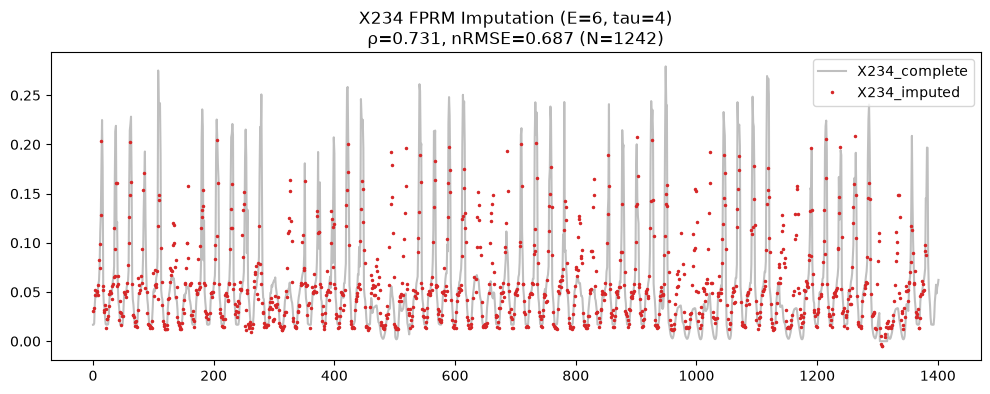

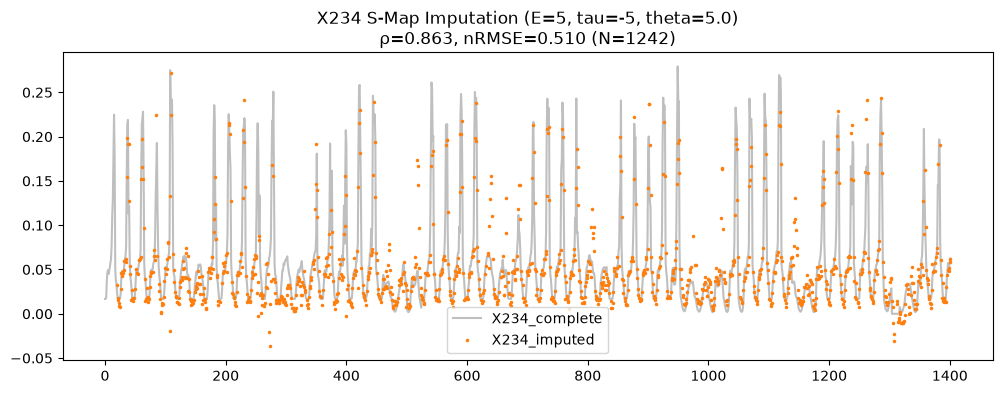

E=9 training views: 100%|██████████████████| 651/651 [00:00<00:00, 1700.21it/s]


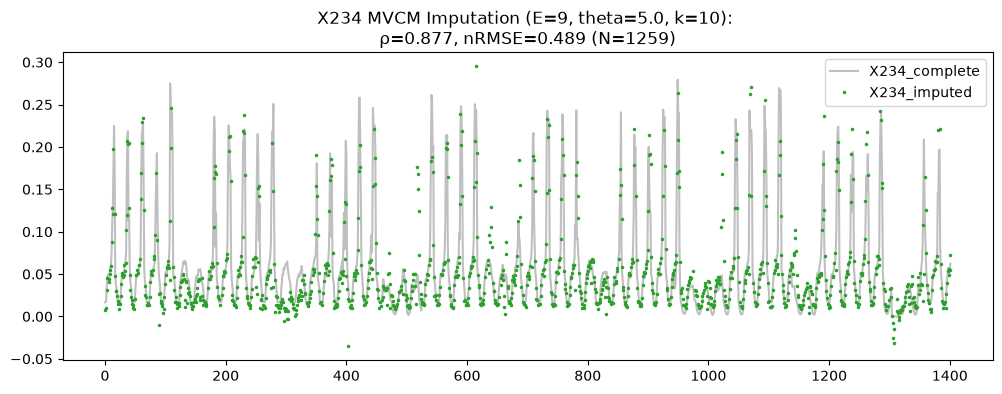

In [24]:
system_name = 'road'
full = 'X1'
partial = random.choice(SYSTEMS[system_name]['df'].columns[1:])
df = SYSTEMS[system_name]['df'][[full, partial]].copy()
missing_frac = 0.9
seed = 42

# FPRM Imputation
E_fprm, tau_fprm = SYSTEMS[system_name]['E_reported'], SYSTEMS[system_name]['tau_reported']
fprm_result = fprm_impute(df, missing_frac, full, partial, E_fprm, tau_fprm, showPlot=True, seed=seed, eng=None)

# S-map Imputation
E_list = [1, 5, 9]
tau_list = [-1, -5, -9]
theta_list = [1.,5.,9.]

exclusionRadius = 10                      # Used only in training step, not for final cross-map
use_pyedm = False

result_smap = smap_impute(df=df, missing_frac=missing_frac, full=full, partial=partial, E_list=E_list, tau_list=tau_list, theta_list=theta_list,
                     exclusionRadius=exclusionRadius, showPlot=True, seed=seed, use_pyedm=use_pyedm)

# MVCM Imputation
lags = lags_for_search(E_list, tau_list)  # same lags as the S-map search (plus positive lags)

k_list = [10,20,50,100]
use_self_lags = True
min_candidates_per_gap = 100
min_train_overlap = 20
exhaustive = False
show_warnings = False                      # False hides the embedding-coverage warnings

result_mvcm = mvcm_impute(df=df, missing_frac=missing_frac, full=full, partial=partial, lags=lags, tau_list=tau_list,
                     E_list=E_list, theta_list=theta_list, k_list=k_list, exclusionRadius=exclusionRadius,
                     min_candidates_per_gap=min_candidates_per_gap, min_train_overlap=min_train_overlap,
                     use_self_lags=use_self_lags, exhaustive=exhaustive, showPlot=True, seed=seed, parallel=True,
                     show_progress=True, use_pyedm=use_pyedm, n_folds=5, show_warnings=show_warnings)

In [25]:
# Verify that results are the same betwen pyEDM S-map and vectorized S-map

t0 = time.time()
result = smap_impute(df=df, missing_frac=missing_frac, full=full, partial=partial, E_list=E_list, tau_list=tau_list, theta_list=theta_list,
                     exclusionRadius=exclusionRadius, showPlot=False, seed=seed, use_pyedm = True)
t1 = time.time()
result_vec = smap_impute(df=df, missing_frac=missing_frac, full=full, partial=partial, E_list=E_list, tau_list=tau_list, theta_list=theta_list,
                     exclusionRadius=exclusionRadius, showPlot=False, seed=seed, use_pyedm = False)
t2 = time.time()

print(f'Time to run classic S-map: {t1-t0:.3f}')
print(f'Time to run vectorized S-map: {t2-t1:.3f}')

s1 = result['result_df'][f'{partial}_imputed']
s2 = result_vec['result_df'][f'{partial}_imputed']
same_mask = s1.notna().equals(s2.notna())
num_imputed = s1.notna().sum()
print(f"Imputed same points?: {same_mask} ({num_imputed} points imputed)")

# 1. Check max absolute difference and mean absolute difference
diff = (s1 - s2).abs()
max_diff, mean_diff = diff.max(), diff.mean()
print(f"Max Absolute Difference:  {max_diff:.2e}")
print(f"Mean Absolute Difference: {mean_diff:.2e}")

# 2. Count how many values differ beyond a floating-point tolerance (e.g., 1e-5)
tol = 1e-5
num_differing_points = (diff > tol).sum()
print(f"Data points differing by > {tol}: {num_differing_points} / {num_imputed}")

Time to run classic S-map: 0.335
Time to run vectorized S-map: 0.115
Imputed same points?: True (1242 points imputed)
Max Absolute Difference:  1.58e-15
Mean Absolute Difference: 7.33e-17
Data points differing by > 1e-05: 0 / 1242


## 7. Sweep Functions

The sweep runs the methods over multiple variables, seeds, and missingness levels.
* `impute_all_methods` - runs every method on one variable with one mask, by calling `smap_impute` and `mvcm_impute`.
* `score_methods` - scores the methods on shared imputed rows. Also records diagnostics (tuning-set ρ, the chosen parameters, MVCM view/coverage counts and run time).
* `run_one` / `run_sweep` - write one CSV per job into `out_dir/shards`, run jobs in parallel, and skip jobs that already finished cleanly, so a stopped sweep resumes where it left off (jobs that errored are retried; their traceback is stored in the shard).

`make_cfg` collects every setting in one dict. Its hash names the results, so changing a setting never mixes old and new results.

FPRM needs MATLAB, so it is not part of the parallel sweep. `run_fprm_pass` and `add_fprm` (below `run_sweep`) run it afterwards in the main process on the same masks, and re-score all three methods on the test rows that every method predicted. This needs the predictions that `run_one` now saves to `out_dir/preds` (jobs finished before that change are re-run once).

In [26]:
def make_cfg(full='X1', methods=('smap', 'mvcm'), E_list=(1,5,9), tau_list=(-1,-5,-9), theta_list=(1.,5.,9.), k_list=(10,20,50,100),
             exclusionRadius=10, min_candidates_per_gap=100, min_train_overlap=20, exhaustive=False, use_self_lags=True,
             n_folds=5, use_pyedm=False, code_version='v1'):
    """All settings that define a comparison. Its hash names the output files, so changing any value (including code_version) starts 
       a fresh set of results."""
    return dict(full=full, methods=list(methods), E_list=list(E_list), tau_list=list(tau_list), theta_list=list(theta_list),
                k_list=list(k_list), exclusionRadius=exclusionRadius, min_candidates_per_gap=min_candidates_per_gap,
                min_train_overlap=min_train_overlap, exhaustive=exhaustive, use_self_lags=use_self_lags,
                n_folds=n_folds, use_pyedm=use_pyedm, code_version=code_version)

def impute_all_methods(df, full, partial, missing_frac, seed, cfg, max_views=None, show_warnings=False):
    """Run every method in cfg['methods'] on ONE variable with ONE train/test mask.
       A method that crashes is recorded in 'errors' (traceback in 'tracebacks') and the others still run.
       Returns dict(imputed={method: full-length vector, NaN outside the test rows},
                    selected={method: chosen parameters / diagnostics}, timing={...}, errors={...}, tracebacks={...},
                    details={method: the full smap_impute / mvcm_impute output, for plotting and inspection})."""
    imputed, selected, timing, errors, tracebacks, details = {}, {}, {}, {}, {}, {}

    def attempt(name, fn):
        t0 = time.perf_counter()
        try:
            out, errors[name] = fn(), ''
        except Exception as e:
            out, errors[name] = None, f'{type(e).__name__}: {e}'[:300]
            tracebacks[name] = traceback.format_exc()
        timing[name] = time.perf_counter() - t0
        return out

    # 1. Univariate S-map
    if 'smap' in cfg['methods']:
        r = attempt('smap', lambda: smap_impute(
            df=df, missing_frac=missing_frac, full=full, partial=partial, E_list=cfg['E_list'],
            tau_list=cfg['tau_list'], theta_list=cfg['theta_list'], exclusionRadius=cfg['exclusionRadius'],
            showPlot=False, seed=seed, use_pyedm=cfg['use_pyedm']
        ))
        if r is not None:
            details['smap'] = r
            imputed['smap'] = r['result_df'][f'{partial}_imputed'].to_numpy(float)
            selected['smap'] = dict(sel_E=r['params']['E'], sel_tau=r['params']['tau'], sel_theta=r['params']['theta'],
                                    tune_rho=r['train_rho'], params=json.dumps(r['params'], default=str))

    # 2. MVCM (given the same lags as the S-map search, plus the mirrored positive lags)
    if 'mvcm' in cfg['methods']:
        r = attempt('mvcm', lambda: mvcm_impute(
            df=df, missing_frac=missing_frac, full=full, partial=partial, lags=lags_for_search(cfg['E_list'], cfg['tau_list']),
            tau_list=cfg['tau_list'], E_list=cfg['E_list'], theta_list=cfg['theta_list'], k_list=cfg['k_list'],
            exclusionRadius=cfg['exclusionRadius'], min_candidates_per_gap=cfg['min_candidates_per_gap'],
            min_train_overlap=cfg['min_train_overlap'], use_self_lags=cfg['use_self_lags'], exhaustive=cfg['exhaustive'],
            max_views=max_views, showPlot=False, seed=seed, parallel=False, use_pyedm=cfg['use_pyedm'],
            n_folds=cfg['n_folds'], show_warnings=show_warnings
        ))
        if r is not None:
            dg, p = r['diagnostics'], r['params']
            details['mvcm'] = r
            imputed['mvcm'] = r['result_df'][f'{partial}_imputed'].to_numpy(float)
            selected['mvcm'] = dict(sel_E=p['E'], sel_theta=p['theta'], sel_k=p['k'], tune_rho=dg['best_cv_rho'],
                                    n_pool=dg['n_pool'].get(p['E']), n_cand=dg['n_cand'].get(p['E']),
                                    n_views_used=dg['n_views_used'], n_test_unfillable=dg['n_test_unfillable'],
                                    n_test_undercovered=dg['n_test_undercovered'], skipped_E=json.dumps(dg['skipped_E']),
                                    params=json.dumps({k: v for k, v in p.items() if k != 'lags'}, default=str))
            
    return dict(imputed=imputed, selected=selected, timing=timing, errors=errors, tracebacks=tracebacks, details=details)

In [27]:
def score_methods(imputed, truth, maskTrn, timing, selected, base):
    """One result row per method.
    Metrics are computed two ways:
        *_common : only on test rows where EVERY method made a prediction (fair, like-for-like comparison)
        *_own    : on whatever rows that method predicted (so methods with lower coverage are not penalised)
    tune_rho (from `selected`) is the method's own tuning-set estimate of rho; compare it with rho_own to spot over-optimistic tuning."""
    imp = pd.DataFrame(imputed)
    common = imp.dropna() if len(imp.columns) else imp
    common_rows = common.index.to_numpy()
    rows = []
    for m in imp.columns:
        p = imp[m].to_numpy(float)
        own = np.isfinite(p)
        mc = _metrics(truth[common_rows], common[m].to_numpy(float))
        mo = _metrics(truth[own], p[own])
        rows.append({**base, 'method': m, 'n_common': len(common_rows), 'n_own': int(own.sum()),
                     'coverage': own.sum() / base['n_test'],
                     'pred_on_train_rows': bool(np.isfinite(p[maskTrn]).any()),      # should always be False
                     'rho_common': mc['rho'], 'rmse_common': mc['rmse'], 'nrmse_common': mc['nrmse'],
                     'rho_own': mo['rho'], 'nrmse_own': mo['nrmse'],
                     'time_s': timing.get(m, np.nan), 'error': '',
                     **selected.get(m, {})})
    return rows

In [28]:
def _job_id(job, cfg_id):
    return f"{cfg_id}__{job['partial']}__s{job['seed']}__f{job['missing_frac']}__c{job['cap'] or 0}__L{job['L'] or 0}"

def _is_done(shard):
    """Done = shard has no error rows AND the matching preds file exists (jobs from before this change are re-run once)."""
    pred = shard.parent.parent / 'preds' / shard.name
    if not (shard.exists() and pred.exists()):
        return False
    try:
        return not (pd.read_csv(shard, usecols=['error'])['error'].fillna('') != '').any()
    except Exception:
        return False

def run_one(job, df_pair, cfg, cfg_id, out_dir):
    """One job = one (variable, seed, missing_frac, cap). Runs all methods, scores them, writes one shard CSV
    plus a preds CSV (one column per method, NaN outside the test rows, and the exact `observed` train mask)."""
    jid = _job_id(job, cfg_id)
    shard, pred_path = Path(out_dir) / 'shards' / f'{jid}.csv', Path(out_dir) / 'preds' / f'{jid}.csv'
    if _is_done(shard):
        return
    partial, seed, frac, cap = job['partial'], job['seed'], job['missing_frac'], job['cap']
    full, df = cfg['full'], df_pair

    run = impute_all_methods(df, full, partial, frac, seed, cfg, max_views=cap)

    truth = df[partial].to_numpy(float)
    maskTrn = make_observed(df, frac, full, seed)[partial].to_numpy()
    n_train = int(maskTrn.sum())
    base = dict(config_id=cfg_id, partial=partial, seed=seed, missing_frac=frac,
                max_views=int(cap or 0), series_len=len(df), n_train=n_train, n_test=len(df) - n_train)

    rows = score_methods(run['imputed'], truth, maskTrn, run['timing'], run['selected'], base)
    rows += [{**base, 'method': name, 'error': err, 'time_s': run['timing'].get(name, np.nan),
              'traceback': run['tracebacks'].get(name, '')[-1500:]} for name, err in run['errors'].items() if err]

    pred_path.parent.mkdir(parents=True, exist_ok=True)
    tmp = pred_path.with_suffix('.tmp')
    pd.DataFrame({**run['imputed'], 'observed': maskTrn}).to_csv(tmp, index_label='row')
    os.replace(tmp, pred_path)
    tmp = shard.with_suffix('.tmp')                     # write-then-rename so a killed job never leaves a half file
    pd.DataFrame(rows).to_csv(tmp, index=False)
    os.replace(tmp, shard)                              # shard is written LAST: it marks the job as done

def config_id(cfg):
    return hashlib.sha1(json.dumps(cfg, sort_keys=True, default=str).encode()).hexdigest()[:8]

def load_results(out_dir, cfg_id=None):
    """Concatenate all shards in out_dir (optionally only those from one config)."""
    res = pd.concat([pd.read_csv(p) for p in sorted((Path(out_dir) / 'shards').glob('*.csv'))], ignore_index=True)
    res['error'] = res['error'].fillna('')
    return res if cfg_id is None else res[res.config_id == cfg_id].reset_index(drop=True)

def run_sweep(df_all, full, partials, seeds, missing_fracs, cfg, caps=(None,), Ls=(None,),
              out_dir='sweep_out', n_jobs=-1, verbose=10):
    """Run run_one over every (variable, seed, missing_frac, cap, series length) in parallel and return the results."""
    out = Path(out_dir)
    (out / 'shards').mkdir(parents=True, exist_ok=True)
    cfg_id = config_id(cfg)
    (out / f'config_{cfg_id}.json').write_text(json.dumps(cfg, indent=2, default=str))

    jobs = [dict(partial=p, seed=s, missing_frac=f, cap=c, L=L)
            for p in partials for s in seeds for f in missing_fracs for c in caps for L in Ls]
    todo = [j for j in jobs if not _is_done(out / 'shards' / f'{_job_id(j, cfg_id)}.csv')]
    random.Random(0).shuffle(todo)                      # even coverage if you stop early; balances long and short jobs
    print(f'config {cfg_id}: {len(todo)} of {len(jobs)} jobs to run')

    def pair(j):                                        # only the two columns this job needs
        d = df_all[[full, j['partial']]]
        return d.iloc[:j['L']] if j['L'] else d

    with parallel_config(backend='loky', inner_max_num_threads=1):
        Parallel(n_jobs=n_jobs, verbose=verbose)(delayed(run_one)(j, pair(j), cfg, cfg_id, out) for j in todo)
    return load_results(out, cfg_id)

In [29]:
def run_fprm_pass(system, res, out_root='sweep_out'):
    """For every (variable, seed, missing_frac) job in `res` (results[system]), run FPRM with the paper's (E, tau) on the
    mask make_observed gives, and save the result to {out_root}/{system}/fprm/{job}.csv.  Resumable: existing files are skipped.
    Not part of the joblib sweep: engines can't be pickled and one MATLAB engine per worker is heavy."""
    s = SYSTEMS[system]; df_all, full = s['df'], s['full']
    E, tau = s['E_reported'], s['tau_reported']
    d = Path(out_root) / system / 'fprm'; d.mkdir(parents=True, exist_ok=True)
    jobs = res[res.error == ''][['partial', 'seed', 'missing_frac', 'max_views', 'config_id']].drop_duplicates()
    failed = []
    for r in jobs.itertuples():
        job = dict(partial=r.partial, seed=r.seed, missing_frac=r.missing_frac, cap=int(r.max_views) or None, L=None)
        f = d / f'{_job_id(job, r.config_id)}.csv'
        if f.exists():
            continue
        pair = df_all[[full, r.partial]]
        try:
            t0 = time.perf_counter()
            out = fprm_impute(pair, r.missing_frac, full, r.partial, E, tau, seed=r.seed)
            imp = out['result_df'][f'{r.partial}_imputed'].to_numpy(float)
            elapsed = time.perf_counter() - t0
        except Exception as e:
            failed.append((r.partial, r.seed, repr(e)[:150])); continue
        tmp = f.with_suffix('.tmp')                       # write-then-rename, as run_one does
        pd.DataFrame({'fprm': imp, 'time_s': elapsed,
                     'E': out['params']['E'], 'tau': out['params']['tau']}).to_csv(tmp, index_label='row')
        os.replace(tmp, f)
    print(f'{system}: FPRM done (E={E}, tau={tau}); {len(failed)} failed', failed[:3] if failed else '')
    return failed

# def run_fprm_pass(system, res, out_root='sweep_out'):
#     """For every (variable, seed, missing_frac) job in `res` (results[system]), run FPRM with the paper's (E, tau) on the
#     mask make_observed gives, and save the result to {out_root}/{system}/fprm/{job}.csv.  Resumable: existing files are skipped.
#     Not part of the joblib sweep: engines can't be pickled and one MATLAB engine per worker is heavy."""
#     s = SYSTEMS[system]; df_all, full = s['df'], s['full']
#     E, tau = s['E_reported'], s['tau_reported']
#     d = Path(out_root) / system / 'fprm'; d.mkdir(parents=True, exist_ok=True)
#     eng = get_matlab_engine()
#     jobs = res[res.error == ''][['partial', 'seed', 'missing_frac', 'max_views', 'config_id']].drop_duplicates()
#     for r in jobs.itertuples():
#         job = dict(partial=r.partial, seed=r.seed, missing_frac=r.missing_frac, cap=int(r.max_views) or None, L=None)
#         f = d / f'{_job_id(job, r.config_id)}.csv'
#         if f.exists():
#             continue
#         pair = df_all[[full, r.partial]]
#         maskTrn = make_observed(pair, r.missing_frac, full, r.seed)[r.partial].to_numpy()
#         t0 = time.perf_counter()
#         imp = fprm_impute(pair[full], pair[r.partial], maskTrn, E, tau, eng)
#         pd.DataFrame({'fprm': imp, 'time_s': time.perf_counter() - t0}).to_csv(f, index_label='row')
#     print(f'{system}: FPRM done (E={E}, tau={tau})')

# Add FPRM to the results; all three methods are re-scored on the rows every method predicted
def add_fprm(system, res, out_root='sweep_out'):
    s = SYSTEMS[system]; df_all = s['df']
    out_dir = Path(out_root) / system
    metric_cols = ['n_common', 'rho_common', 'rmse_common', 'nrmse_common']
    pieces = []
    for (frac, seed, partial), gp in res[res.error == ''].groupby(['missing_frac', 'seed', 'partial']):
        job = dict(partial=partial, seed=seed, missing_frac=frac, cap=int(gp.max_views.iloc[0]) or None, L=None)
        jid = _job_id(job, gp.config_id.iloc[0])
        pr = pd.read_csv(out_dir / 'preds' / f'{jid}.csv', index_col='row')
        fr = pd.read_csv(out_dir / 'fprm' / f'{jid}.csv', index_col='row')
        maskTrn = pr.pop('observed').to_numpy(bool)
        imputed = {m: pr[m].to_numpy(float) for m in ('smap', 'mvcm')}
        imputed['fprm'] = fr['fprm'].to_numpy(float)
        base = {c: gp[c].iloc[0] for c in ['config_id', 'partial', 'seed', 'missing_frac', 'max_views',
                                           'series_len', 'n_train', 'n_test']}
        E_used = int(fr['E'].iloc[0]) if 'E' in fr else s['E_reported']
        tau_used = int(fr['tau'].iloc[0]) if 'tau' in fr else s['tau_reported']
        new = pd.DataFrame(score_methods(imputed, df_all[partial].to_numpy(float), maskTrn,
                                         {'fprm': float(fr['time_s'].iloc[0])},
                                         {'fprm': dict(sel_E=E_used, sel_tau=tau_used)}, base)).set_index('method')
        upd = gp.set_index('method').copy()
        for c in metric_cols:
            upd[c] = new[c].reindex(upd.index).to_numpy().copy()
        pieces.append(pd.concat([upd, new.loc[['fprm']]]).reset_index())
    return pd.concat(pieces, ignore_index=True)

### 7a. Run full sweep

In [30]:
DEFAULTS      = dict(E_list=[1,5,9], tau_list=[-1,-5,-9], theta_list=[1.,5.,9.], max_views=None)
RUN_SYSTEMS   = list(SYSTEMS)
SEEDS         = range(5)
MISSING_FRACS = [0.9]
N_JOBS        = -1
OUT_ROOT      = 'sweep_out'
CODE_VERSION  = 'v1'

In [31]:
def system_cfg(name):
    """The sweep config of one system (shared by run_system and diagnose_one so they always use the same settings)."""
    s = SYSTEMS[name]
    return make_cfg(full=s['full'], E_list=s['E_list'], tau_list=s['tau_list'], code_version=CODE_VERSION)

def run_system(name, seeds=SEEDS, missing_fracs=MISSING_FRACS,n_jobs=N_JOBS, out_root=OUT_ROOT):
    s = SYSTEMS[name]
    cfg = system_cfg(name)
    partials = [c for c in s['df'].columns if c != s['full']]
    out_dir = f'{out_root}/{name}'
    for frac in missing_fracs:
        run_sweep(s['df'], s['full'], partials, seeds=seeds, missing_fracs=[frac], cfg=cfg,
                  caps=[s['max_views']], out_dir=out_dir, n_jobs=n_jobs)
    return load_results(out_dir, config_id(cfg))

write_matlab_files()
_ENG = None
results = {}
for attempt in range(3):
    for name in RUN_SYSTEMS:
        print(f'\n===== {name} =====')
        results[name] = run_system(name)
    if all((r.error == '').all() for r in results.values()):
        break


===== ecology =====
config 9dec4f25: 10 of 10 jobs to run


[Parallel(n_jobs=-1)]: Using backend LokyBackend with 24 concurrent workers.
[Parallel(n_jobs=-1)]: Done   3 out of  10 | elapsed:    5.6s remaining:   13.0s
[Parallel(n_jobs=-1)]: Done   5 out of  10 | elapsed:    6.2s remaining:    6.2s
[Parallel(n_jobs=-1)]: Done   7 out of  10 | elapsed:    6.8s remaining:    2.9s



===== lorenz3D =====
config 9dec4f25: 10 of 10 jobs to run


[Parallel(n_jobs=-1)]: Done  10 out of  10 | elapsed:    9.9s finished
[Parallel(n_jobs=-1)]: Using backend LokyBackend with 24 concurrent workers.
[Parallel(n_jobs=-1)]: Done   3 out of  10 | elapsed:   18.8s remaining:   43.9s
[Parallel(n_jobs=-1)]: Done   5 out of  10 | elapsed:   19.2s remaining:   19.2s
[Parallel(n_jobs=-1)]: Done   7 out of  10 | elapsed:   23.1s remaining:    9.9s



===== lorenz120D =====
config 9dec4f25: 595 of 595 jobs to run


...

[Parallel(n_jobs=-1)]: Using backend LokyBackend with 24 concurrent workers.
[Parallel(n_jobs=-1)]: Done   2 tasks      | elapsed:    7.2s
[Parallel(n_jobs=-1)]: Done  13 tasks      | elapsed:   10.5s
[Parallel(n_jobs=-1)]: Done  24 tasks      | elapsed:   14.3s
[Parallel(n_jobs=-1)]: Done  37 tasks      | elapsed:   20.7s
[Parallel(n_jobs=-1)]: Done  50 tasks      | elapsed:   26.3s
[Parallel(n_jobs=-1)]: Done  65 tasks      | elapsed:   32.0s
[Parallel(n_jobs=-1)]: Done  80 tasks      | elapsed:   39.0s
[Parallel(n_jobs=-1)]: Done  97 tasks      | elapsed:   45.2s
[Parallel(n_jobs=-1)]: Done 114 tasks      | elapsed:   52.0s
[Parallel(n_jobs=-1)]: Done 133 tasks      | elapsed:  1.0min
[Parallel(n_jobs=-1)]: Done 152 tasks      | elapsed:  1.1min
[Parallel(n_jobs=-1)]: Done 173 tasks      | elapsed:  1.3min
[Parallel(n_jobs=-1)]: Done 194 tasks      | elapsed:  1.4min
[Parallel(n_jobs=-1)]: Done 217 tasks      | elapsed:  1.6min
[Parallel(n_jobs=-1)]: Done 240 tasks      | elapsed:  


===== exchange =====
config 9dec4f25: 255 of 255 jobs to run


[Parallel(n_jobs=-1)]: Using backend LokyBackend with 24 concurrent workers.
[Parallel(n_jobs=-1)]: Done   2 tasks      | elapsed:   17.1s
[Parallel(n_jobs=-1)]: Done  13 tasks      | elapsed:   23.3s
[Parallel(n_jobs=-1)]: Done  24 tasks      | elapsed:   39.6s
[Parallel(n_jobs=-1)]: Done  37 tasks      | elapsed:   49.0s
[Parallel(n_jobs=-1)]: Done  50 tasks      | elapsed:  1.1min
[Parallel(n_jobs=-1)]: Done  65 tasks      | elapsed:  1.3min
[Parallel(n_jobs=-1)]: Done  80 tasks      | elapsed:  1.5min
[Parallel(n_jobs=-1)]: Done  97 tasks      | elapsed:  1.8min
[Parallel(n_jobs=-1)]: Done 114 tasks      | elapsed:  2.1min
[Parallel(n_jobs=-1)]: Done 133 tasks      | elapsed:  2.4min
[Parallel(n_jobs=-1)]: Done 152 tasks      | elapsed:  2.7min
[Parallel(n_jobs=-1)]: Done 173 tasks      | elapsed:  3.0min
[Parallel(n_jobs=-1)]: Done 194 tasks      | elapsed:  3.4min
[Parallel(n_jobs=-1)]: Done 234 out of 255 | elapsed:  4.0min remaining:   21.7s
[Parallel(n_jobs=-1)]: Done 255 out 


===== wind =====
config 9dec4f25: 1150 of 1150 jobs to run


[Parallel(n_jobs=-1)]: Using backend LokyBackend with 24 concurrent workers.
[Parallel(n_jobs=-1)]: Done   2 tasks      | elapsed:    3.5s
[Parallel(n_jobs=-1)]: Done  13 tasks      | elapsed:    5.1s
[Parallel(n_jobs=-1)]: Done  24 tasks      | elapsed:    6.6s
[Parallel(n_jobs=-1)]: Done  37 tasks      | elapsed:    9.8s
[Parallel(n_jobs=-1)]: Done  50 tasks      | elapsed:   12.5s
[Parallel(n_jobs=-1)]: Done  65 tasks      | elapsed:   14.5s
[Parallel(n_jobs=-1)]: Done  80 tasks      | elapsed:   17.5s
[Parallel(n_jobs=-1)]: Done  97 tasks      | elapsed:   21.2s
[Parallel(n_jobs=-1)]: Done 114 tasks      | elapsed:   24.2s
[Parallel(n_jobs=-1)]: Done 133 tasks      | elapsed:   27.6s
[Parallel(n_jobs=-1)]: Done 152 tasks      | elapsed:   31.4s
[Parallel(n_jobs=-1)]: Done 173 tasks      | elapsed:   35.8s
[Parallel(n_jobs=-1)]: Done 194 tasks      | elapsed:   38.9s
[Parallel(n_jobs=-1)]: Done 217 tasks      | elapsed:   43.4s
[Parallel(n_jobs=-1)]: Done 240 tasks      | elapsed:  

#### FPRM pass and three-method results

Runs FPRM (MATLAB engine, one process) on the sweep's masks and adds it to the results. `results3` is what the tables below use.

In [32]:
results3 = {}
for name in RUN_SYSTEMS:
    print(f'\n===== FPRM: {name} =====')
    run_fprm_pass(name, results[name])
    results3[name] = add_fprm(name, results[name])


===== FPRM: ecology =====
ecology: FPRM done (E=3, tau=3); 0 failed 

===== FPRM: lorenz3D =====
lorenz3D: FPRM done (E=3, tau=3); 0 failed 

===== FPRM: lorenz120D =====
lorenz120D: FPRM done (E=4, tau=3); 0 failed 

===== FPRM: rossler120D =====
rossler120D: FPRM done (E=5, tau=2); 0 failed 

===== FPRM: road =====
road: FPRM done (E=6, tau=4); 0 failed 

===== FPRM: eeg =====
eeg: FPRM done (E=3, tau=3); 0 failed 

===== FPRM: exchange =====
exchange: FPRM done (E=4, tau=4); 0 failed 

===== FPRM: wind =====
wind: FPRM done (E=4, tau=6); 0 failed 


## 7b. Summary Functions

In [33]:
def method_table(res, by=('missing_frac',), metrics=('rho_common', 'nrmse_common'), unit='variable', order=METHOD_ORDER, paired=True):
    ok = res[res.error == ''].copy()
    if paired:
        n_ok = ok.groupby(['partial', 'seed', 'missing_frac', 'max_views', 'series_len']).method.transform('nunique')
        ok = ok[n_ok == len(order)]

    # NEW: sample-size counts, taken from the runs BEFORE any averaging
    key = [*by, 'method']
    n_runs = ok.groupby(key).size().rename('n_runs')
    n_partials = ok.groupby(key).partial.nunique().rename('n_partials')
    seeds_per_var = ok.groupby([*key, 'partial']).seed.nunique().groupby(key)
    n_seeds_min, n_seeds_max = seeds_per_var.min().rename('n_seeds_min'), seeds_per_var.max().rename('n_seeds_max')
    counts = pd.concat([n_partials, n_runs, n_seeds_min, n_seeds_max], axis=1).reset_index()
    counts['n_seeds'] = np.where(counts.n_seeds_min == counts.n_seeds_max,
                                 counts.n_seeds_max.astype(str),
                                 counts.n_seeds_min.astype(str) + '–' + counts.n_seeds_max.astype(str))

    if unit == 'variable':
        ok = ok.groupby([*by, 'method', 'partial'])[list(metrics)].mean().reset_index()
    g = ok.groupby([*by, 'method'])[list(metrics)]
    out = g.agg(['mean', 'std', 'count'])
    out.columns = [f'{m}_{s}' for m, s in out.columns]
    out = out.reset_index()
    out = out.merge(counts[[*key, 'n_partials', 'n_seeds', 'n_runs']], on=key, how='left')   # NEW
    out['method'] = pd.Categorical(out['method'], categories=list(order), ordered=True)
    out = out.sort_values([*by, 'method']).reset_index(drop=True)
    for m in metrics:
        out[m.replace('_common', '')] = out[f'{m}_mean'].round(3).astype(str) + ' ± ' + out[f'{m}_std'].round(3).astype(str)
    out['n_units'] = out[f'{metrics[0]}_count']
    return out


def plot_rho_by_method(res, title=''):
    """Per-variable rho (averaged over seeds) for each method, with mean ± SD in black."""
    pv = res[res.error == ''].groupby(['missing_frac', 'method', 'partial']).rho_common.mean().reset_index()
    fracs = sorted(pv.missing_frac.unique())
    fig, axes = plt.subplots(1, len(fracs), figsize=(5.2 * len(fracs), 4.2), sharey=True, squeeze=False)
    rng = np.random.default_rng(0)
    for ax, f in zip(axes[0], fracs):
        for i, m in enumerate(METHOD_ORDER):
            v = pv[(pv.missing_frac == f) & (pv.method == m)].rho_common.to_numpy()
            if len(v) == 0: continue
            ax.scatter(i + rng.uniform(-0.18, 0.18, len(v)), v, s=8, alpha=0.35, color=METHOD_COLORS[m], linewidths=0)
            ax.errorbar(i, v.mean(), yerr=v.std(ddof=1) if len(v) > 1 else 0, fmt='o', color='black', capsize=4, ms=6, zorder=3)
        ax.set_xticks(range(len(METHOD_ORDER)), [METHOD_LABELS[m] for m in METHOD_ORDER], fontsize=8)
        ax.set_title(f'{f:.0%} missing'); ax.grid(axis='y', alpha=0.3)
    axes[0][0].set_ylabel('ρ (per variable, mean over seeds)')
    fig.suptitle(f'{title} imputation accuracy across variables (black: mean ± SD)'); plt.tight_layout(); plt.show()

### 7c. Diagnostics

* `check_results` - sanity checks over the sweep output: failed runs (with the most common error), unpaired runs, MVCM coverage, predictions on training rows, tuning-ρ vs. test-ρ gap, run time. Prints what looks wrong.
* `worst_cases` - the (variable, seed) runs where MVCM does worst relative to S-map.
* `diagnose_one` - re-runs ONE (system, variable, seed) exactly as the sweep does, in this process, with plots, tracebacks and the tuning grids.

In [34]:
def check_results(results, min_coverage=0.95, max_tune_gap=0.2):
    """Sanity checks on the sweep output (results = {system: DataFrame}). Prints what looks wrong; returns a per-(system, method) summary.
    tune_gap = tune_rho - rho_own: how much better the method's own tuning-set rho was than its test rho (large = tuning is optimistic)."""
    summary, problems = [], []
    for name, res in results.items():
        ok, bad = res[res.error == ''], res[res.error != '']
        for m in METHOD_ORDER:
            r, n_err = ok[ok.method == m], int((bad.method == m).sum())
            gap = (r['tune_rho'] - r['rho_own']) if 'tune_rho' in r else pd.Series(dtype=float)
            summary.append(dict(system=name, method=m, n_ok=len(r), n_error=n_err,
                                coverage_min=r['coverage'].min(), n_common_min=r['n_common'].min(),
                                rho_nan=int(r['rho_common'].isna().sum()), tune_gap_median=gap.median(),
                                time_median_s=r['time_s'].median() if 'time_s' in r else np.nan,
                                on_train_rows=int(r['pred_on_train_rows'].sum()) if len(r) else 0))
            if n_err:
                problems.append(f"{name}/{m}: {n_err} failed runs; most common error: {bad[bad.method == m]['error'].value_counts().index[0]}")
            if len(r) and r['rho_common'].isna().any():
                problems.append(f"{name}/{m}: rho is NaN in {int(r['rho_common'].isna().sum())} runs (constant or too few predictions)")
            if m == 'mvcm' and len(r) and (r['coverage'] < min_coverage).any():
                problems.append(f"{name}/mvcm: coverage < {min_coverage:.0%} in {int((r['coverage'] < min_coverage).sum())} runs (min {r['coverage'].min():.0%})")
            if len(r) and r['pred_on_train_rows'].any():
                problems.append(f"{name}/{m}: predictions on TRAINING rows in {int(r['pred_on_train_rows'].sum())} runs (should never happen)")
            if gap.notna().any() and gap.median() > max_tune_gap:
                problems.append(f"{name}/{m}: median tuning rho exceeds test rho by {gap.median():.2f} (tuning estimate is optimistic)")
        n_methods = ok.groupby(['partial', 'seed', 'missing_frac']).method.nunique()
        if (n_methods < len(METHOD_ORDER)).any():
            problems.append(f"{name}: {int((n_methods < len(METHOD_ORDER)).sum())} (variable, seed) runs lack a method (method_table(paired=True) skips them)")
    print('\n'.join(['Problems flagged:'] + [' - ' + p for p in problems]) if problems else 'No problems flagged.')
    return pd.DataFrame(summary)


def worst_cases(res, n=10, metric='nrmse_common', method='mvcm', baseline='smap'):
    """The n (variable, seed) runs where `method` is worst relative to `baseline` (delta = method - baseline; for nRMSE, > 0 = worse)."""
    w = res[res.error == ''].pivot_table(index=['partial', 'seed', 'missing_frac'], columns='method', values=metric)
    w['delta'] = w[method] - w[baseline]
    return w.sort_values('delta', ascending=False).head(n).reset_index()


def diagnose_one(system, partial, seed=0, missing_frac=0.9, show_warnings=True, plot=True, with_fprm=True):
    """Re-run ONE (system, variable, seed) exactly as the sweep does (same config, same max_views), with plots and diagnostics.
    Returns the impute_all_methods output; ['details'][method] holds the full smap_impute / mvcm_impute result."""
    s, cfg = SYSTEMS[system], system_cfg(system)
    full = s['full']
    df = s['df'][[full, partial]].copy()
    run = impute_all_methods(df, full, partial, missing_frac, seed, cfg, max_views=s['max_views'], show_warnings=show_warnings)

    for m, err in run['errors'].items():
        if err:
            print(f"--- {m} FAILED: {err}\n{run['tracebacks'].get(m, '')}")
    if not run['imputed']:
        return run

    truth = df[partial].to_numpy(float)
    maskTrn = make_observed(df, missing_frac, full, seed)[partial].to_numpy()
    n_train = int(maskTrn.sum())
    if with_fprm:                                       # FPRM with the paper's (E, tau), on the same mask
        t0 = time.perf_counter()
        run['imputed']['fprm'] = fprm_impute(df[full], df[partial], maskTrn, s['E_reported'], s['tau_reported'])
        run['timing']['fprm'] = time.perf_counter() - t0
        run['selected']['fprm'] = dict(sel_E=s['E_reported'], sel_tau=s['tau_reported'])
    base = dict(config_id=config_id(cfg), partial=partial, seed=seed, missing_frac=missing_frac, max_views=int(s['max_views'] or 0),
                series_len=len(df), n_train=n_train, n_test=len(df) - n_train)
    scores = pd.DataFrame(score_methods(run['imputed'], truth, maskTrn, run['timing'], run['selected'], base))
    cols = ['method', 'n_common', 'coverage', 'rho_common', 'nrmse_common', 'rho_own', 'nrmse_own', 'tune_rho', 'sel_E', 'sel_tau',
            'sel_theta', 'sel_k', 'n_pool', 'n_cand', 'n_views_used', 'n_test_unfillable', 'n_test_undercovered', 'time_s']
    display(scores[[c for c in cols if c in scores]].round(3))

    for m in ('smap', 'mvcm'):
        if m in run['details']:
            print(f'\n{m}: top of the tuning grid'); display(run['details'][m]['parameter_grid'].head(5).round(3))

    if plot:
        imp = pd.DataFrame(run['imputed'])
        common = imp.dropna().index.to_numpy()
        fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 4), gridspec_kw=dict(width_ratios=[2.5, 1]))
        a1.plot(truth, color='lightgray', lw=1, label='truth')
        a1.plot(np.where(maskTrn)[0], truth[maskTrn], 'k.', ms=4, label='observed (train)')
        for m in imp.columns:
            a1.plot(imp.index, imp[m], '.', ms=3, color=METHOD_COLORS.get(m), label=METHOD_LABELS.get(m, m))
            a2.scatter(truth[common], imp.loc[common, m], s=6, alpha=0.5, color=METHOD_COLORS.get(m))
        lim = [np.nanmin(truth), np.nanmax(truth)]
        a2.plot(lim, lim, 'k--', lw=0.8)
        a1.set_title(f'{system} / {partial}, seed={seed}, {missing_frac:.0%} missing'); a1.legend(markerscale=3, fontsize=8)
        a2.set_xlabel('truth'); a2.set_ylabel('imputed'); a2.set_title('test rows predicted by every method')
        plt.tight_layout(); plt.show()
    return run

### 7d. Get the table values

In [35]:
tables = {}
for name, res in results3.items():
    tables[name] = method_table(res)
    print(f'\n===== {name} =====')
    display(tables[name][['missing_frac', 'method', 'rho', 'nrmse', 'n_partials', 'n_seeds', 'n_runs']])

all_tables = pd.concat(tables, names=['system']).reset_index(level='system')
all_tables.to_csv('method_tables.csv', index=False)
pd.concat(results3, names=['system']).reset_index(level='system').to_csv('all_results.csv', index=False)


===== ecology =====


,missing_frac,method,rho,nrmse,n_partials,n_seeds,n_runs
0,0.9,smap,1.0 ± 0.0,0.0 ± 0.0,2,5,10
1,0.9,mvcm,1.0 ± 0.0,0.0 ± 0.0,2,5,10
2,0.9,fprm,1.0 ± 0.0,0.007 ± 0.001,2,5,10



===== lorenz3D =====


,missing_frac,method,rho,nrmse,n_partials,n_seeds,n_runs
0,0.9,smap,0.996 ± 0.004,0.085 ± 0.044,2,5,10
1,0.9,mvcm,0.999 ± 0.001,0.043 ± 0.023,2,5,10
2,0.9,fprm,0.978 ± 0.029,0.169 ± 0.169,2,5,10



===== lorenz120D =====


...

,missing_frac,method,rho,nrmse,n_partials,n_seeds,n_runs
0,0.9,smap,0.968 ± 0.017,0.253 ± 0.063,63,5,315
1,0.9,mvcm,0.981 ± 0.013,0.187 ± 0.058,63,5,315
2,0.9,fprm,0.956 ± 0.023,0.292 ± 0.066,63,5,315



===== exchange =====


,missing_frac,method,rho,nrmse,n_partials,n_seeds,n_runs
0,0.9,smap,0.865 ± 0.143,0.389 ± 0.304,51,5,255
1,0.9,mvcm,0.97 ± 0.036,0.192 ± 0.148,51,5,255
2,0.9,fprm,0.844 ± 0.15,0.421 ± 0.314,51,5,255



===== wind =====


,missing_frac,method,rho,nrmse,n_partials,n_seeds,n_runs
0,0.9,smap,0.767 ± 0.143,0.677 ± 0.189,230,5,1150
1,0.9,mvcm,0.868 ± 0.101,0.499 ± 0.149,230,5,1150
2,0.9,fprm,0.656 ± 0.102,0.765 ± 0.118,230,5,1150


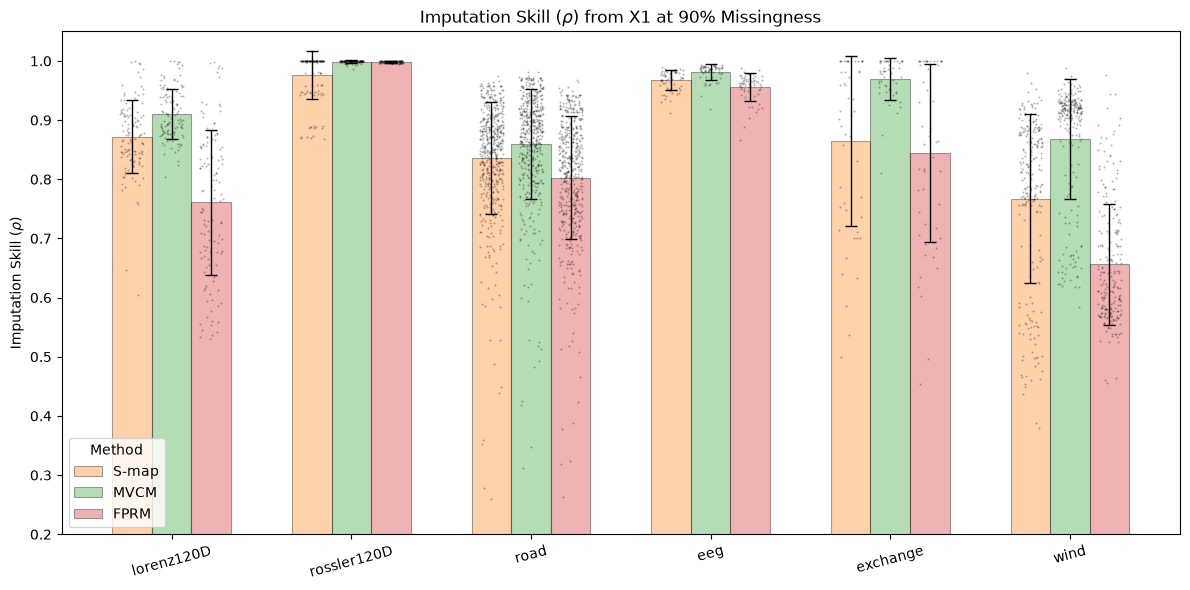

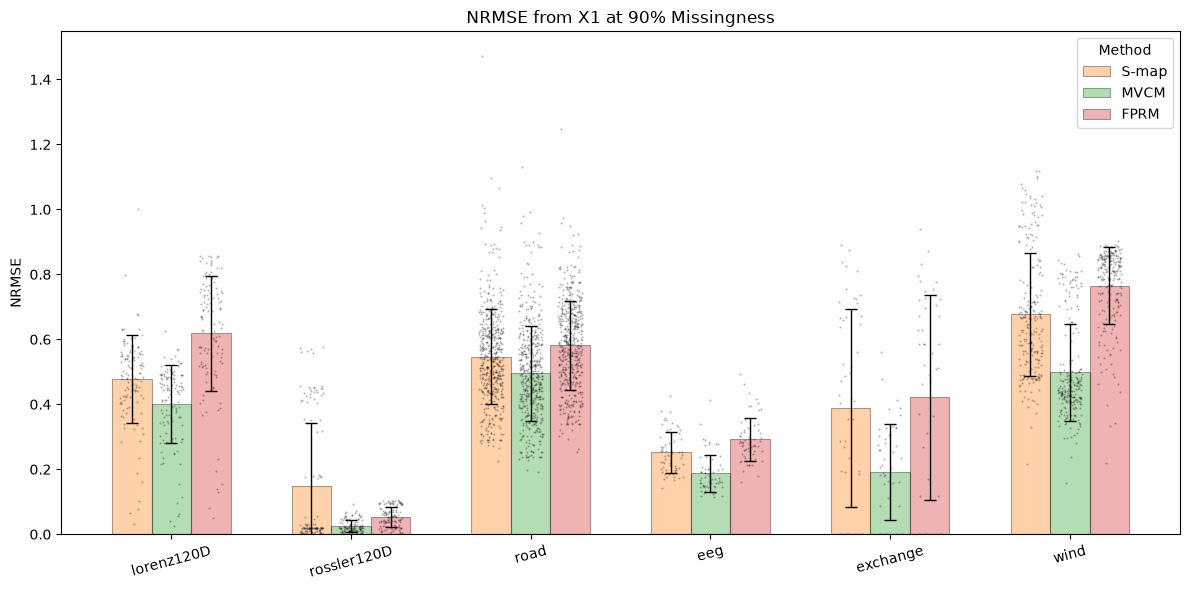

In [44]:
# Visualize results

def plot_imputation_performance(results3, metric="rho", exclude_systems={"ecology", "lorenz3D"}, missingness_pct=90, source_var="X1",):
    """Plots summary bar charts with individual variable data points for either 'rho' or 'nrmse'.
    Parameters
    ----------
    results3 : dict
        Dictionary of DataFrames per system.
    metric : str, optional
        Either 'rho' or 'nrmse' (default is 'rho').
    exclude_systems : set, optional
        Systems to filter out.
    missingness_pct : int, optional
        Missingness percentage for titles.
    source_var : str, optional
        Source variable name for titles.
    """
    # Define metric-dependent mapping parameters
    metric_config = {
    "rho": {
        "target_col": "rho_common",
        "ylabel": r"Imputation Skill ($\rho$)",  # or "Imputation Skill ($\\\\rho$)"
        "title": f"Imputation Skill ($\\rho$) from {source_var} at {missingness_pct}% Missingness",
        "ylim": (0.2, 1.05),
    },
    "nrmse": {
        "target_col": "nrmse_common",
        "ylabel": "NRMSE",
        "title": f"NRMSE from {source_var} at {missingness_pct}% Missingness",
        "ylim": (0.0, None),
    },
    }

    if metric not in metric_config:
        raise ValueError(
            f"Invalid metric '{metric}'. Expected one of: {list(metric_config.keys())}"
        )

    cfg = metric_config[metric]
    target_col = cfg["target_col"]

    # 1. Combine and aggregate data across systems and variables
    df_list = []
    for system_name, df_res in results3.items():
        df_temp = df_res.copy()
        df_temp["system"] = system_name
        df_list.append(df_temp)

    df_all = pd.concat(df_list, ignore_index=True)

    # Filter out excluded systems
    df_all = df_all[~df_all["system"].isin(exclude_systems)]

    # Step A: Average across seeds for each individual variable (partial)
    df_var_level = df_all.groupby(
        ["system", "method", "partial"], as_index=False
    ).agg(val_mean_seeds=(target_col, "mean"))

    # Step B: Summary statistics across variables per system & method
    df_sys_level = df_var_level.groupby(
        ["system", "method"], as_index=False
    ).agg(val_mean=("val_mean_seeds", "mean"), val_sd_vars=("val_mean_seeds", "std"))

    # 2. Setup single figure
    fig, ax = plt.subplots(figsize=(12, 6))

    # Get remaining systems preserving order
    systems_list = [s for s in results3.keys() if s not in exclude_systems]
    n_systems = len(systems_list)
    n_methods = len(METHOD_ORDER)

    bar_width = 0.22
    x = np.arange(n_systems)

    # 3. Plot grouped bars, cross-variable SDs, and jittered dots
    for i, m_key in enumerate(METHOD_ORDER):
        m_label = METHOD_LABELS[m_key]
        color = METHOD_COLORS[m_key]

        # Calculate offset position for each method bar within system group
        offset = (i - (n_methods - 1) / 2) * bar_width
        x_positions = x + offset

        means, stds = [], []
        for sys in systems_list:
            sub = df_sys_level[
                (df_sys_level["system"] == sys) & (df_sys_level["method"] == m_key)
            ]
            if not sub.empty:
                means.append(sub["val_mean"].values[0])
                sd_val = sub["val_sd_vars"].values[0]
                stds.append(0.0 if np.isnan(sd_val) else sd_val)
            else:
                means.append(0)
                stds.append(0)

        # Draw summary bars + SD error caps
        ax.bar(
            x_positions,
            means,
            yerr=stds,
            width=bar_width,
            color=color,
            alpha=0.35,
            edgecolor="black",
            linewidth=0.8,
            capsize=4,
            error_kw={"ecolor": "black", "linewidth": 1.0, "capthick": 1.0},
            label=m_label,
            zorder=1,
        )

        # Overlay individual variable dots inside each corresponding bar
        for sys_idx, sys in enumerate(systems_list):
            var_data = df_var_level[
                (df_var_level["system"] == sys) & (df_var_level["method"] == m_key)
            ]
            if not var_data.empty:
                np.random.seed(42 + sys_idx)
                dot_x = x_positions[sys_idx] + np.random.uniform(
                    -bar_width * 0.3, bar_width * 0.3, len(var_data)
                )
                ax.scatter(
                    dot_x,
                    var_data["val_mean_seeds"],
                    color="black",
                    alpha=0.3,
                    s=2,
                    linewidth=0,
                    zorder=2,
                )

    # Formatting
    ax.set_xticks(x)
    ax.set_xticklabels(systems_list, rotation=15)
    ax.set_ylabel(cfg["ylabel"])

    if cfg["ylim"][1] is not None:
        ax.set_ylim(cfg["ylim"])
    else:
        ax.set_ylim(bottom=cfg["ylim"][0])

    ax.set_title(cfg["title"])
    ax.legend(title="Method", frameon=True, facecolor="white")

    plt.tight_layout()
    return fig, ax

# Plot skill (rho)
fig, ax = plot_imputation_performance(results3, metric="rho")
plt.show()

# Plot error (nrmse)
fig, ax = plot_imputation_performance(results3, metric="nrmse")
plt.show()